# IMPORT LIBRARY

In [1]:
import os
import random
import datetime
import json
import pandas   as pd
import numpy    as np

from tqdm                       import tqdm
from preProcessingDataTEP       import PreProcessData
from utility.matpilotDraw       import MatPlot

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]

# LOADING DATA

In [2]:
# This function is used to load and save data into H5 file
preData     = PreProcessData(config=myConfig)
outputDir   = os.path.expanduser(preData.config["dataDir"])
oriData     = preData.loadCSVDataFile(dir               = outputDir, 
                                      removeHigherThr   = True, 
                                      columnNames       = ["Stripper Level","Stripper Level","Stripper Level"],
                                      thr               = ["down", "down", "up"]) 

# preData.save2H5Format(dir = outputDir, data = oriData)

Process:12875||2025-02-04 10:28:28,895-INFO [preProcessingDataTEP.py:loadCSVDataFile():246]:Loading data from files ...


-------------------------------------- 1
Id
1     -28.181436
2     -27.834543
3     -28.688067
4     -27.183742
5     -27.385509
         ...    
146   -27.123584
147   -26.091481
148   -26.823606
149   -27.459453
150   -27.357289
Name: Stripper Level, Length: 150, dtype: float64 Id
1      53.073862
2      53.073862
3      53.073862
4      53.073862
5      53.073862
         ...    
146    53.073862
147    53.073862
148    53.073862
149    53.111271
150    53.073862
Name: Stripper Level, Length: 150, dtype: float64
Threshold -25.4662594296784
-------------------------------------- 2
Id
1     -25.716820
2     -28.431825
3     -28.035814
4     -27.729405
5     -25.320464
         ...    
146   -27.385686
147   -27.004344
148   -28.367296
149   -27.385385
150   -27.231210
Name: Stripper Level, Length: 150, dtype: float64 Id
1      58.388884
2      57.863837
3      57.512341
4      57.512341
5      57.512341
         ...    
146    57.512341
147    57.512341
148    57.512341
149    57.5123

In [3]:
plot               = MatPlot() 

# ----------------------    
# Reactor, Separator,Stripper
# ----------------------
np.random.seed(1)
random.seed(1)

preData     = PreProcessData(config=myConfig)
outputDir   = os.path.expanduser(preData.config["dataDir"])
rawData             = preData.loadDataFromH5Format(dir = outputDir, case="all")
withRULData         = preData.addRULAndEnvironment(rawData)
withoutInitRawData  = preData.removeInitState(inData= withRULData)


# for idxCase,vlData in rawData.items():
#     print("----------------------------------")
#     print(f'The case {idxCase}: {vlData.shape}')
#     print(vlData)


Process:12875||2025-02-04 10:28:33,417-INFO [preProcessingDataTEP.py:loadDataFromH5Format():285]:Loading data from H5 files ...
Process:12875||2025-02-04 10:28:34,720-INFO [preProcessingDataTEP.py:loadDataFromH5Format():299]:Finish loading data from H5 files at case all...
Process:12875||2025-02-04 10:28:34,924-INFO [preProcessingDataTEP.py:addRULAndEnvironment():347]:Adding rul successfully...


In [4]:
preData.showScenario()

scenario 1: mode 6: reactor     -> separator
scenario 2: mode 4: reactor     -> stripper
scenario 3: mode 6: separator   -> stripper
scenario 4: mode 2: reactor     -> separator    -> stripper
scenario 5: mode 1: reactor     -> stripper     -> separator
scenario 6: mode 5: separator   -> stripper     -> separator
scenario 7: mode 2: reactor     -> separator


In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= withoutInitRawData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

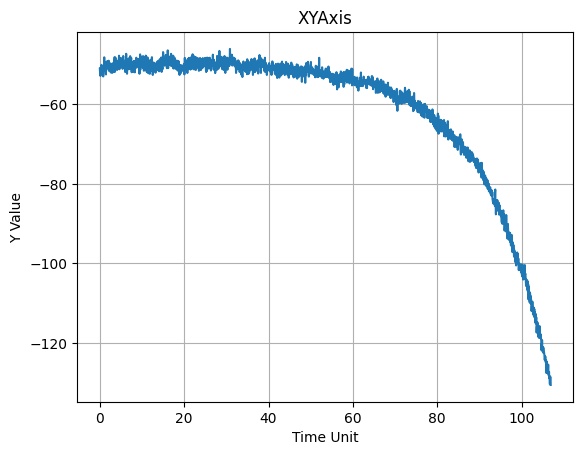

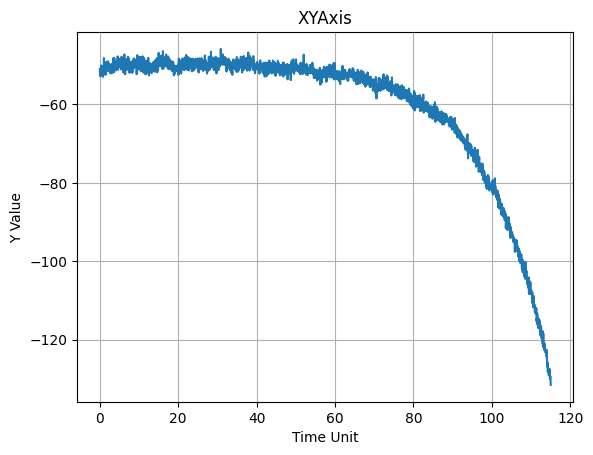

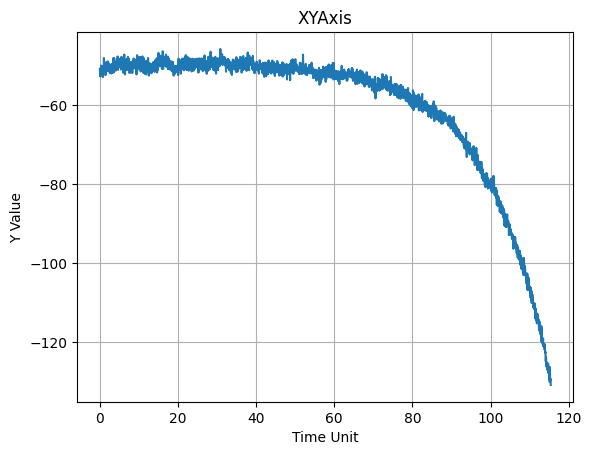

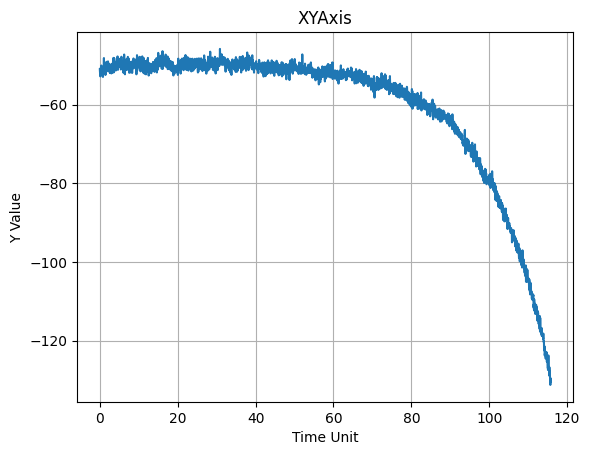

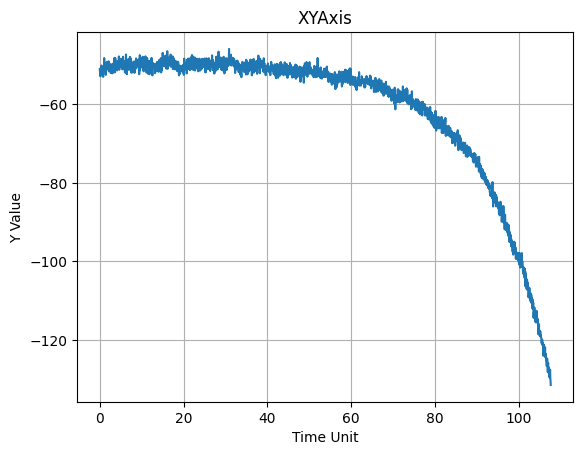

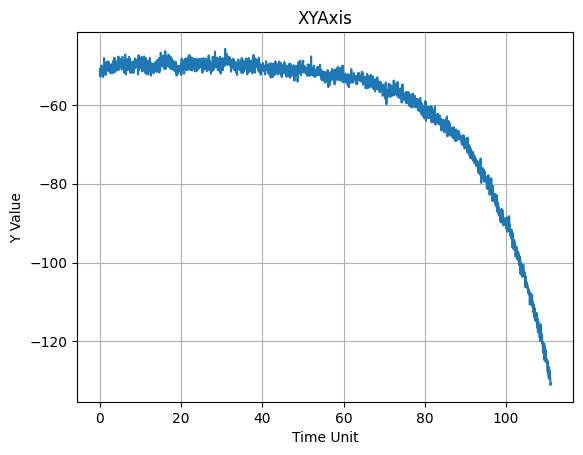

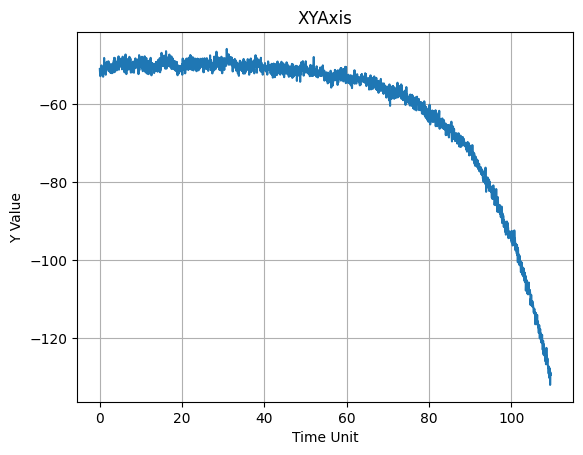

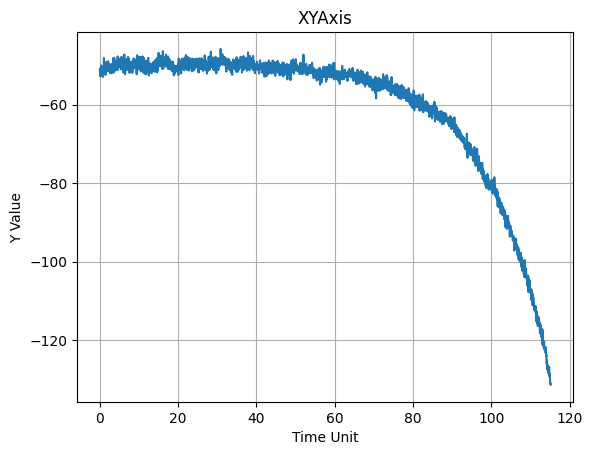

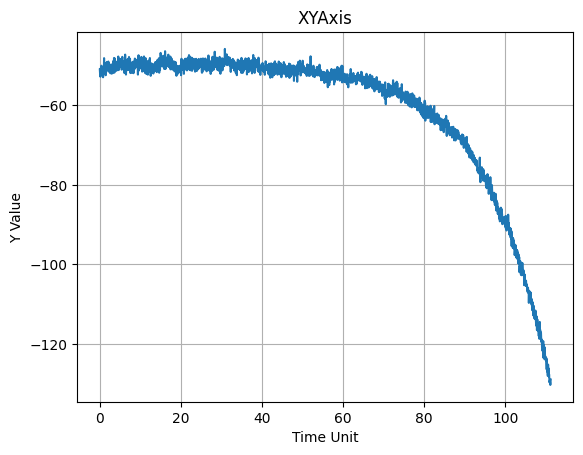

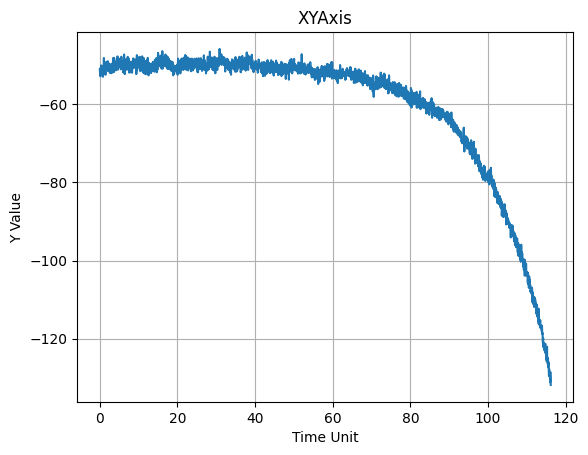

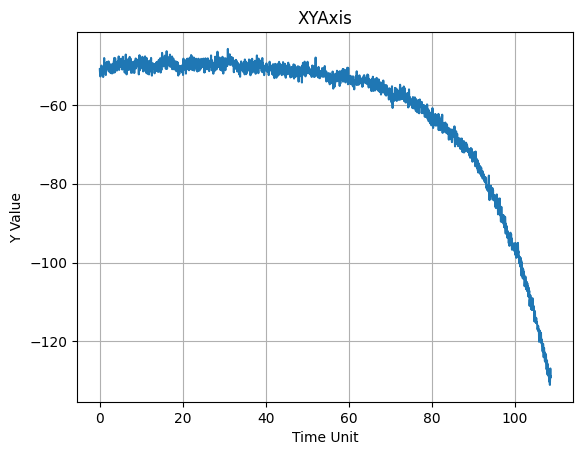

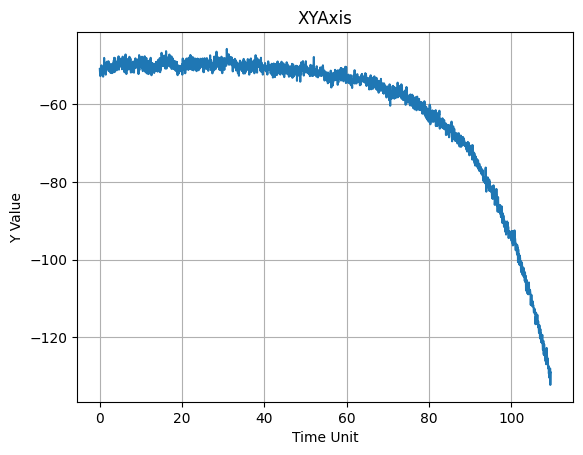

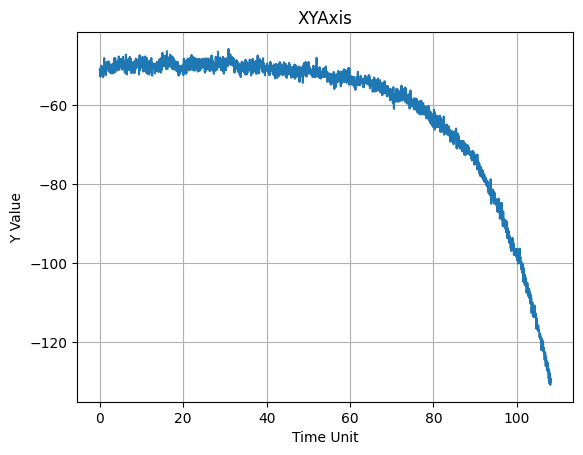

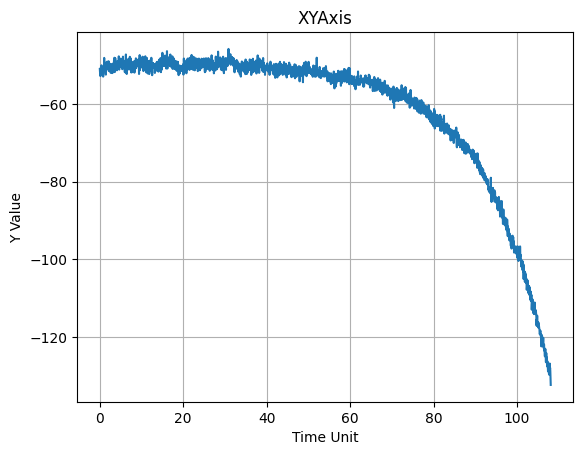

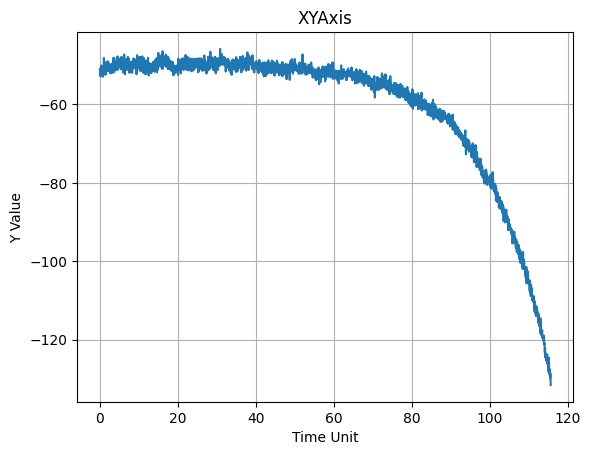

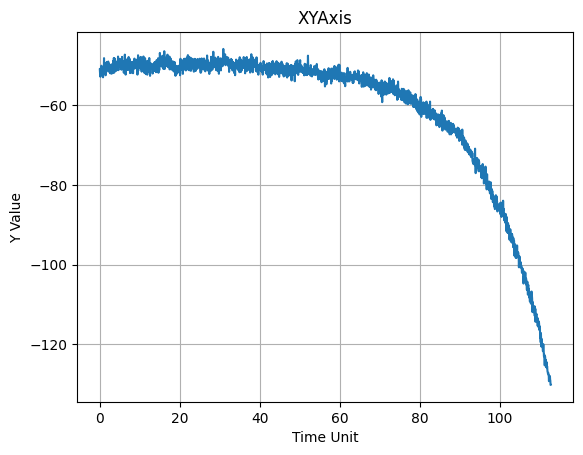

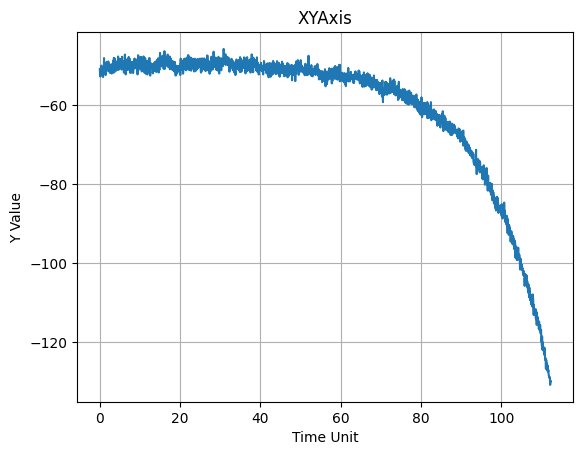

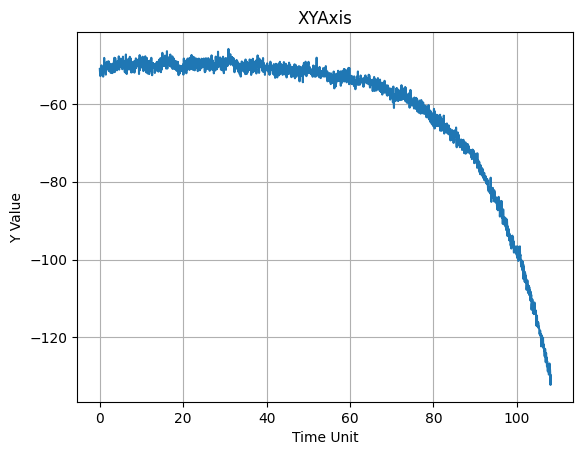

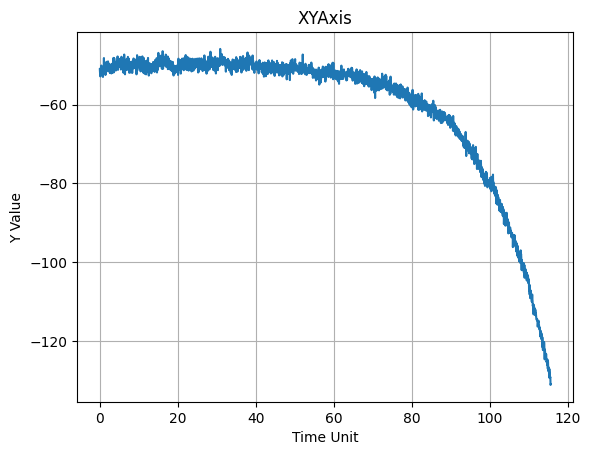

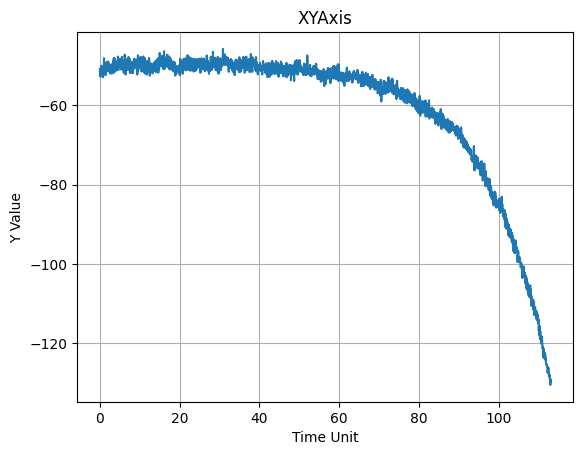

In [12]:
for idx in range(20):
    curTrajectory = preData.getTrajectoryAt(inData= withoutInitRawData, case = 2, idxTrajectory= idx + 1)
    plot.draw2D(curTrajectory["Time"],curTrajectory["Stripper Level"])


In [6]:
cleanData           = preData.cleanData(rawSignal               =   withoutInitRawData,
                                            columnName          =   preData.allWithoutLabel,
                                            getMovingAverage    =   True,
                                            flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

movedData           = preData.movingToPeak(cleanData)


Process:12875||2025-02-04 10:28:43,138-INFO [preProcessingDataTEP.py:cleanData():423]:Cleaning data ...
Process:12875||2025-02-04 10:28:43,139-INFO [preProcessingDataTEP.py:cleanData():436]:Getting average data at case 1 and column D feed ...
Process:12875||2025-02-04 10:28:43,221-INFO [preProcessingDataTEP.py:cleanData():440]:Flipping data at case 1 and column D feed ...
Process:12875||2025-02-04 10:28:43,268-INFO [preProcessingDataTEP.py:cleanData():436]:Getting average data at case 1 and column E Feed ...
Process:12875||2025-02-04 10:28:43,315-INFO [preProcessingDataTEP.py:cleanData():440]:Flipping data at case 1 and column E Feed ...
Process:12875||2025-02-04 10:28:43,365-INFO [preProcessingDataTEP.py:cleanData():436]:Getting average data at case 1 and column A Feed ...
Process:12875||2025-02-04 10:28:43,408-INFO [preProcessingDataTEP.py:cleanData():440]:Flipping data at case 1 and column A Feed ...
Process:12875||2025-02-04 10:28:43,456-INFO [preProcessingDataTEP.py:cleanData():43

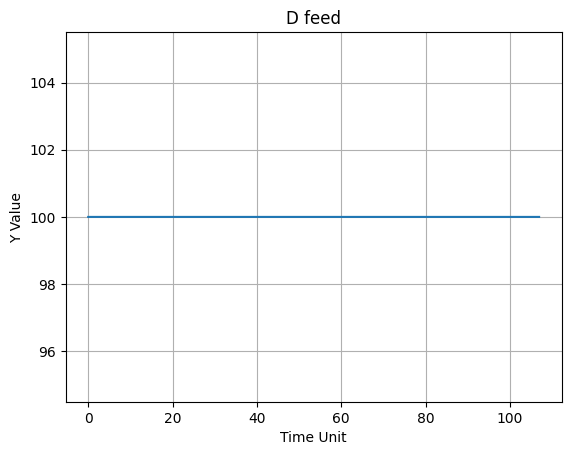

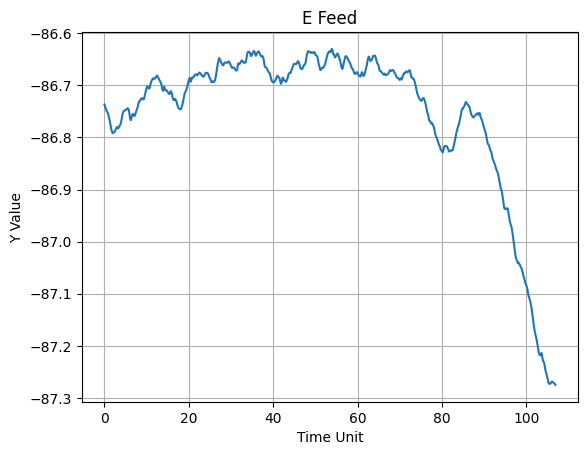

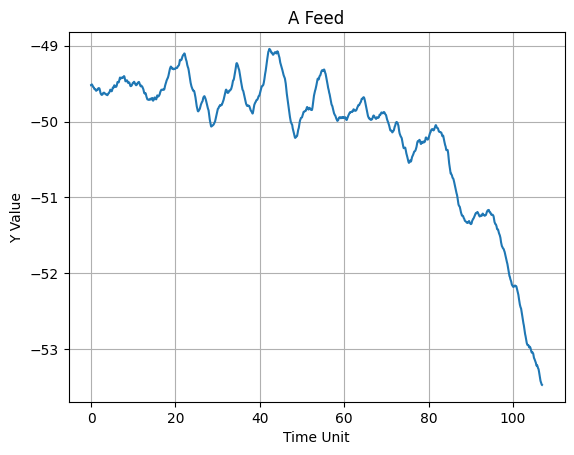

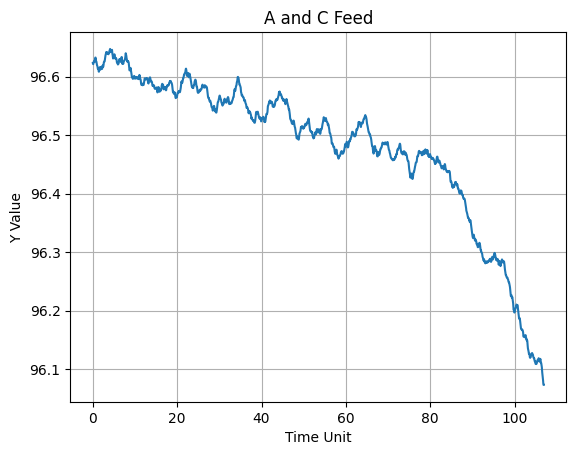

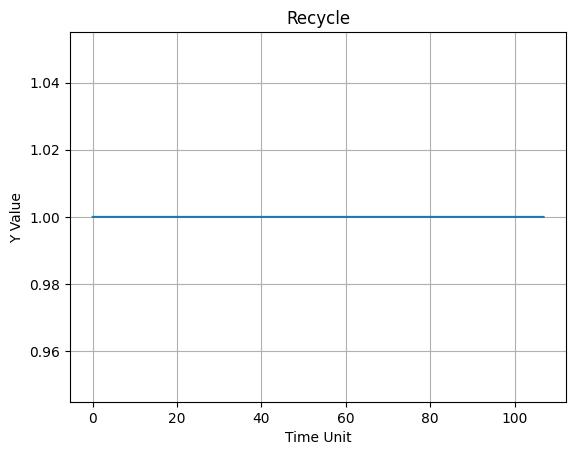

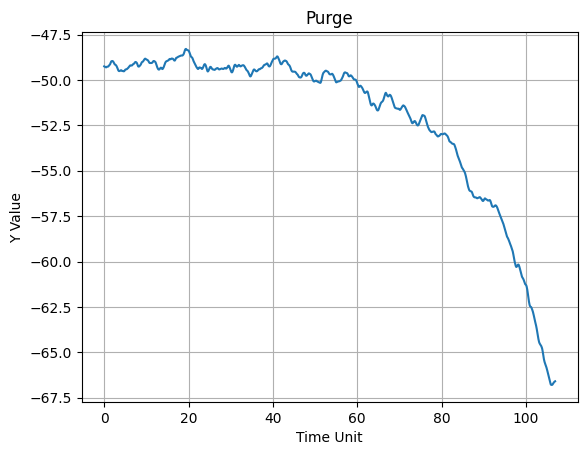

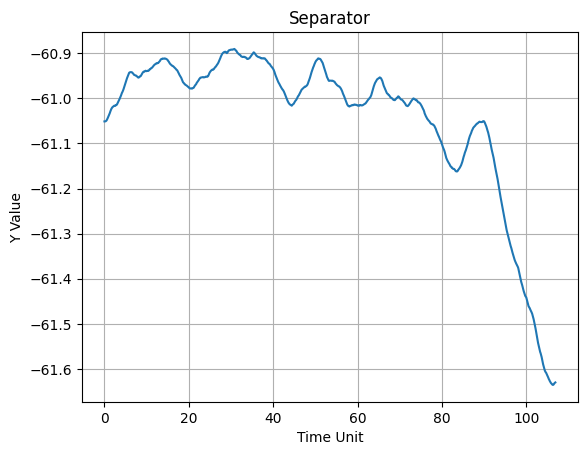

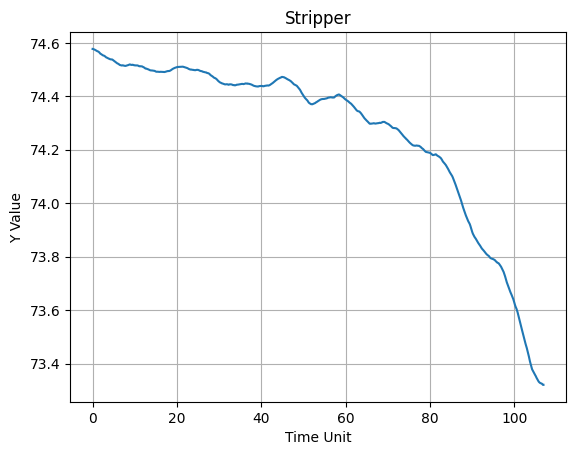

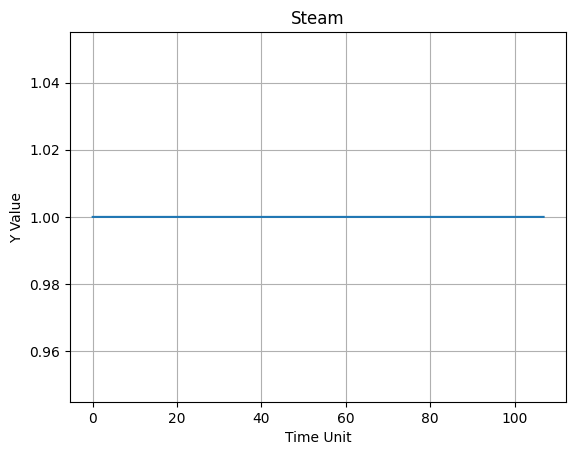

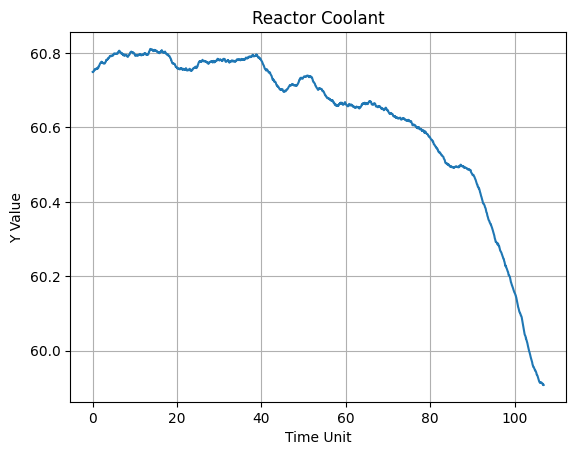

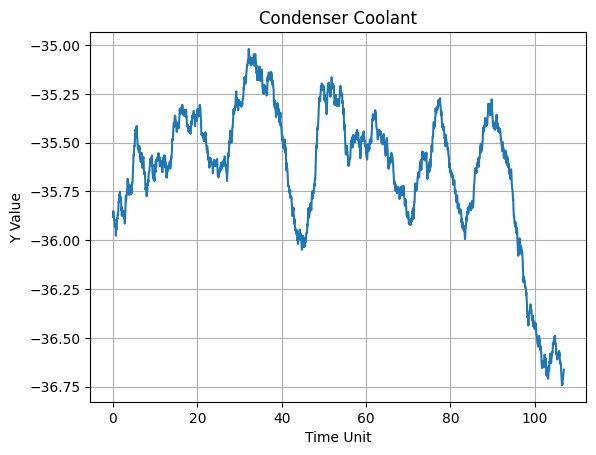

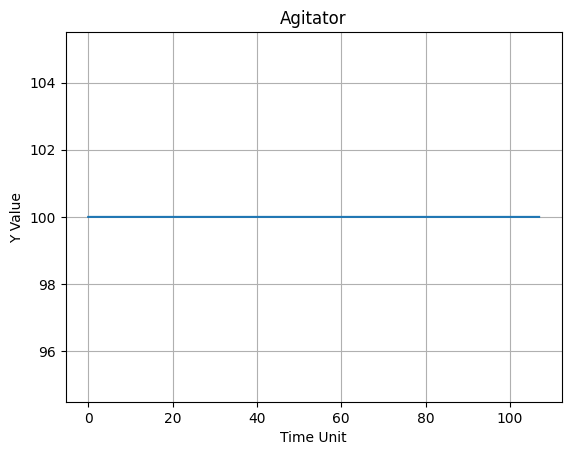

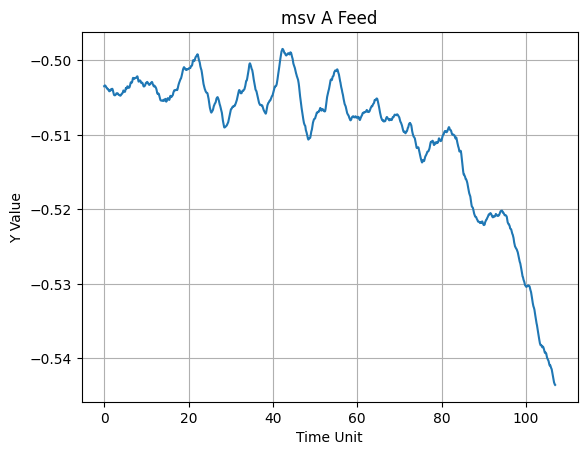

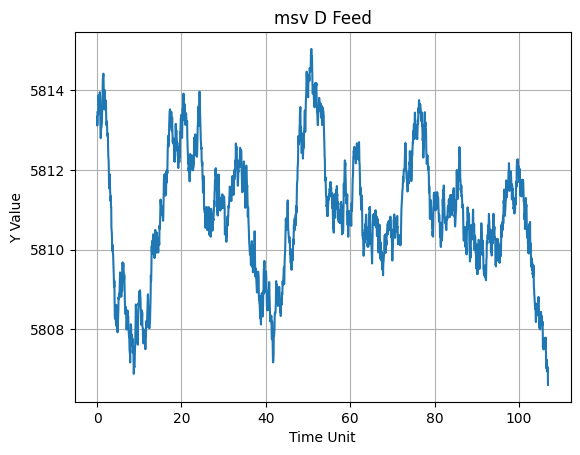

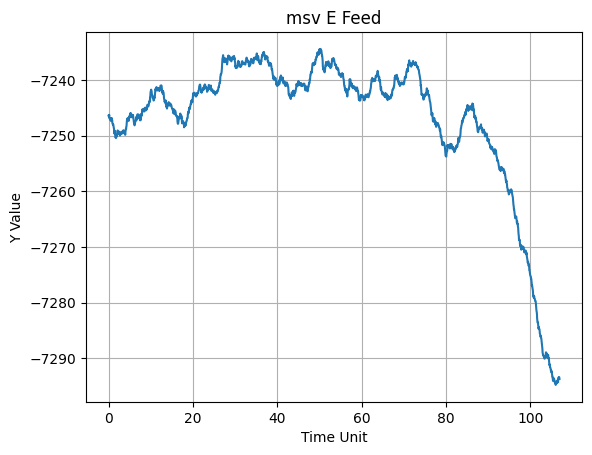

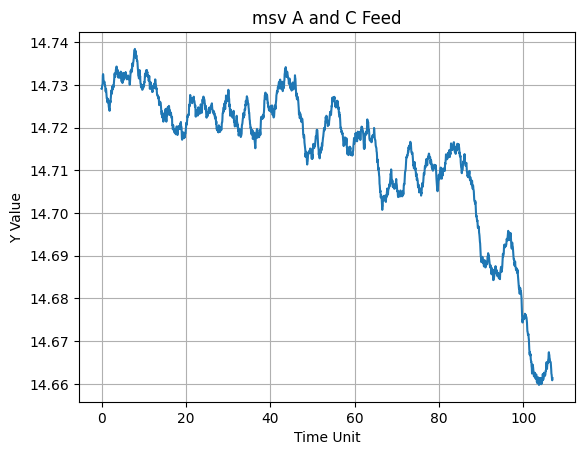

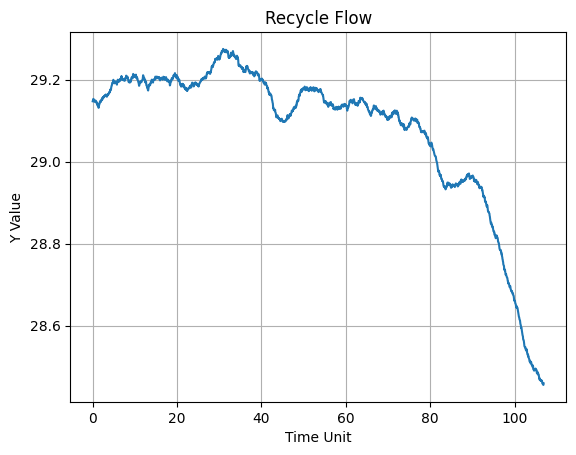

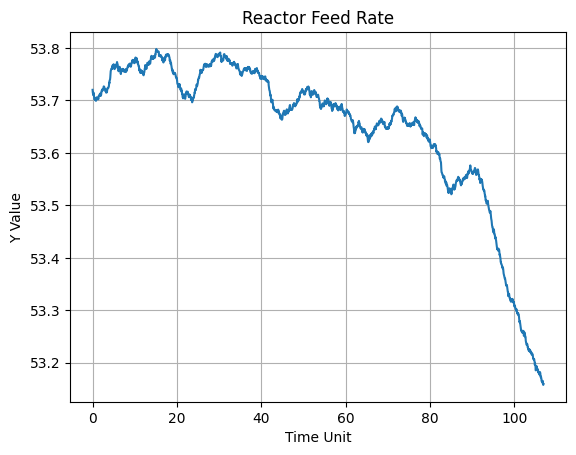

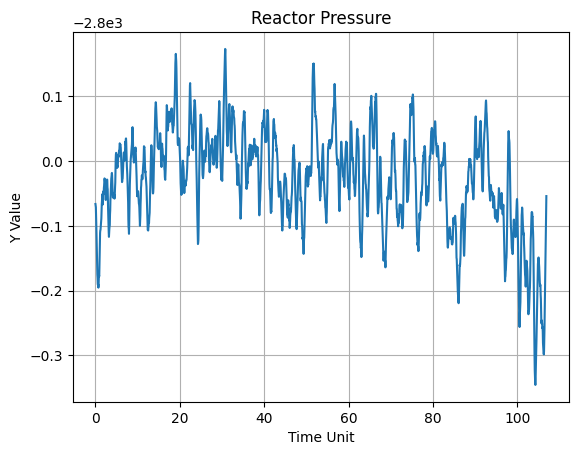

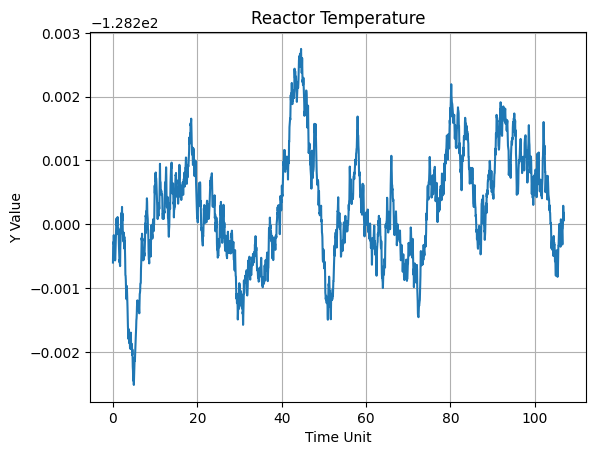

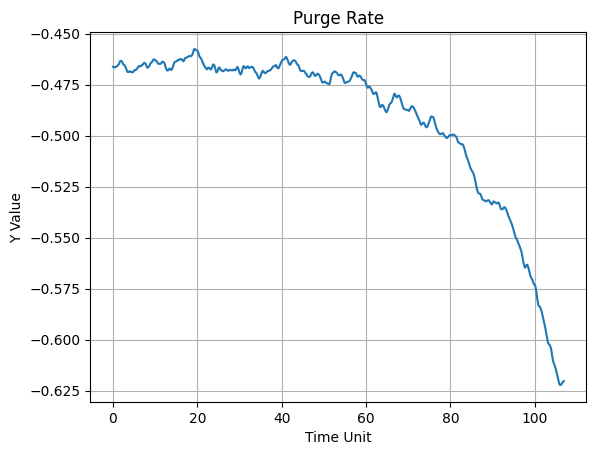

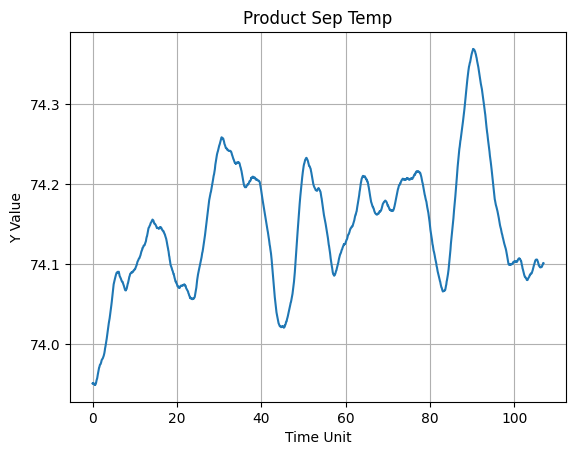

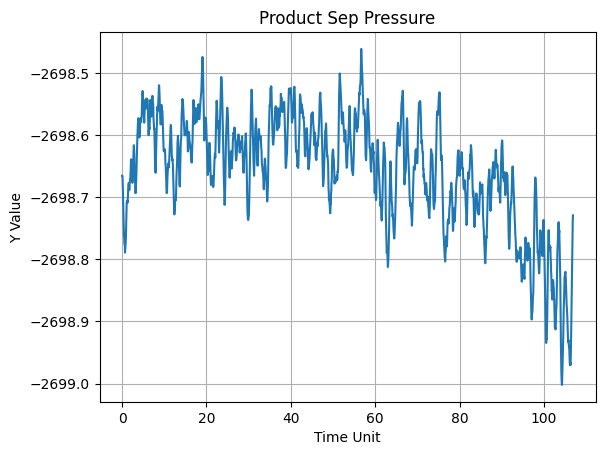

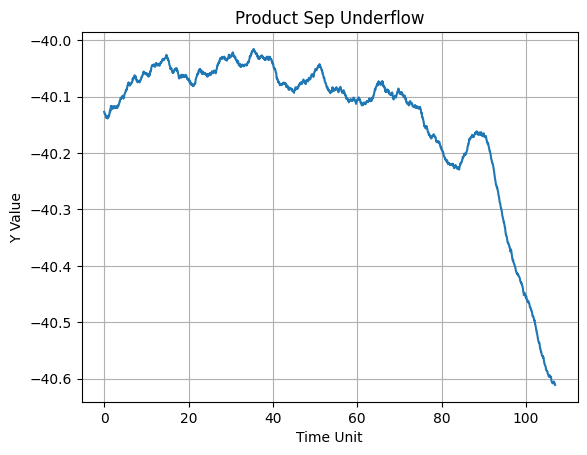

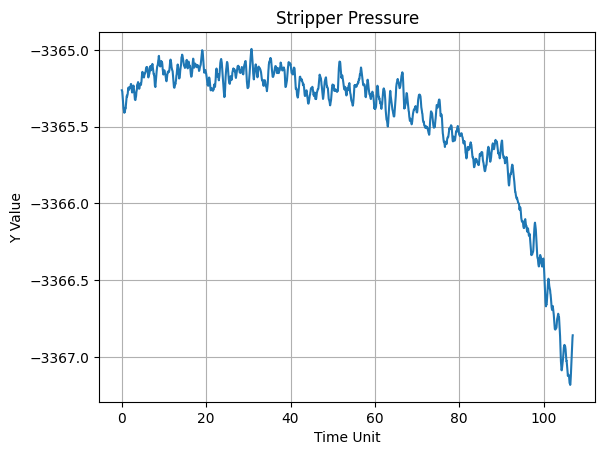

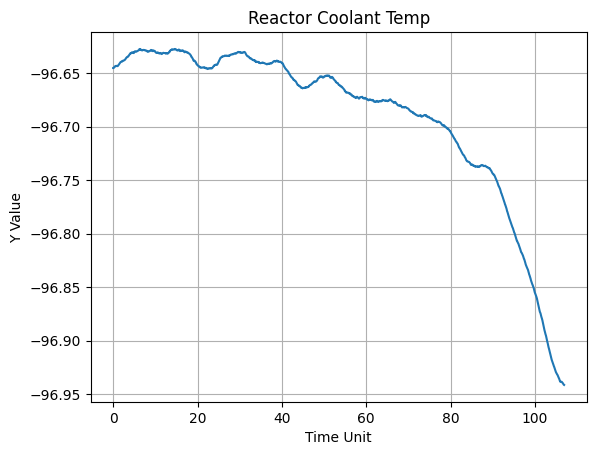

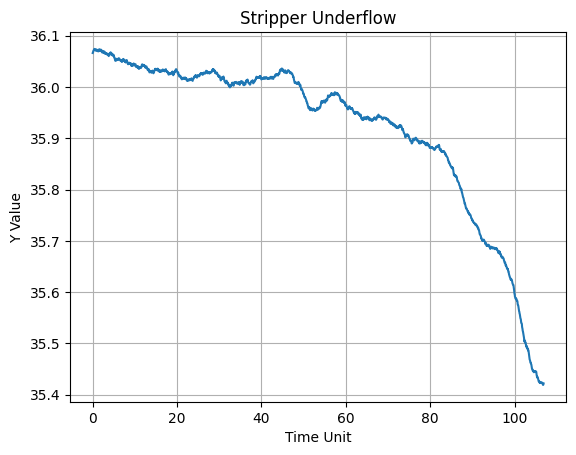

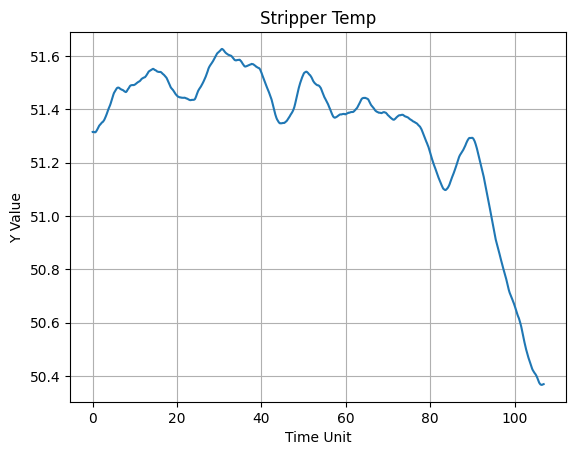

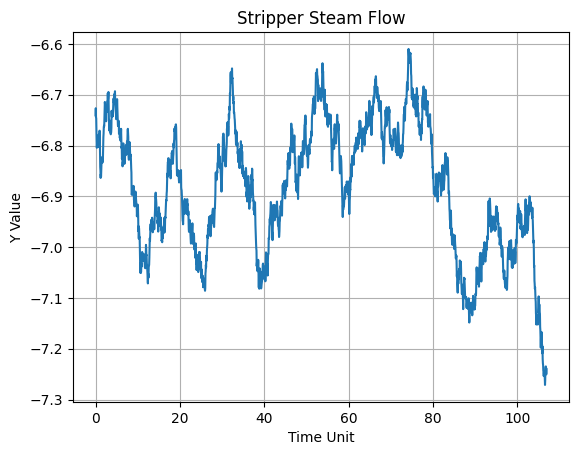

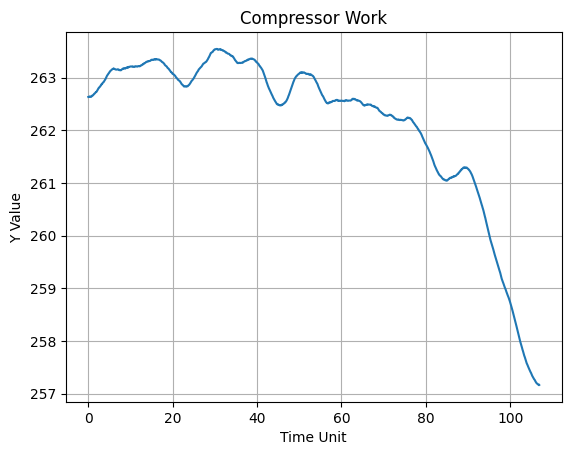

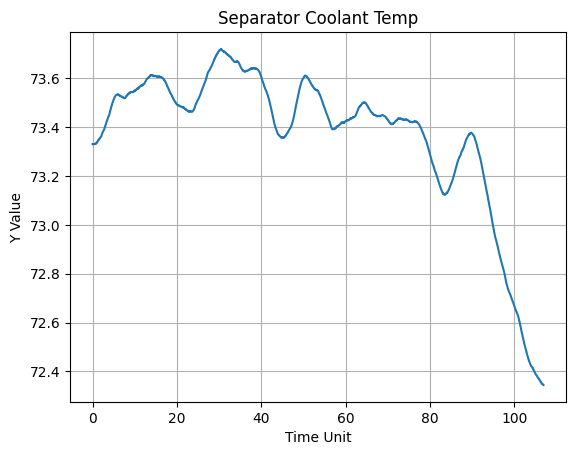

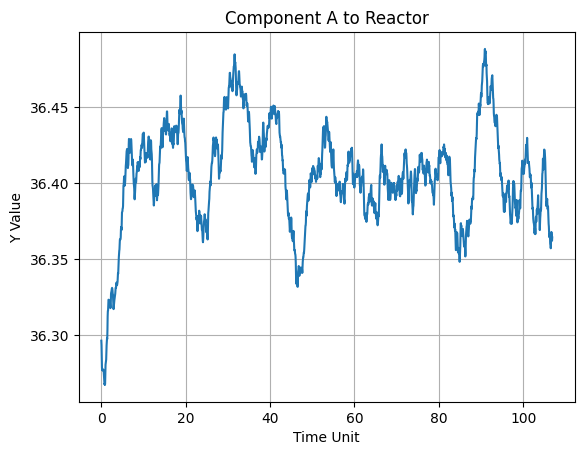

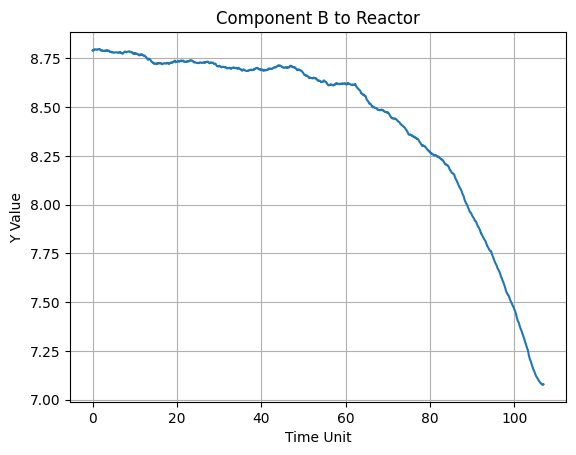

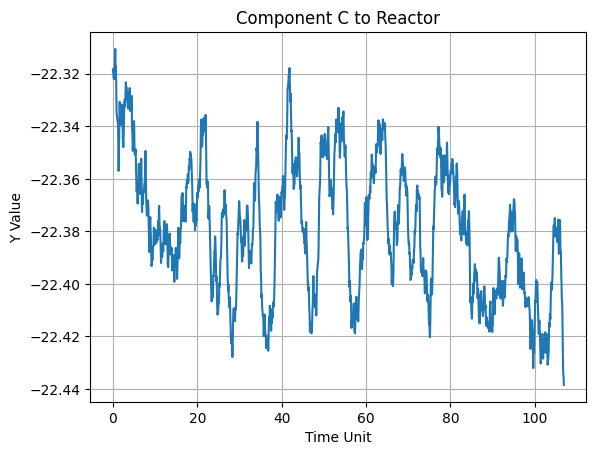

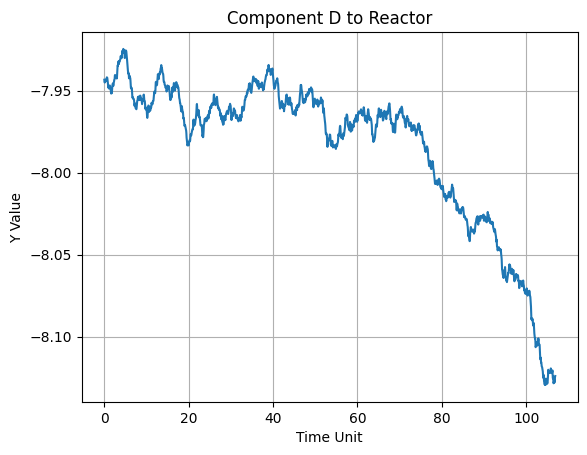

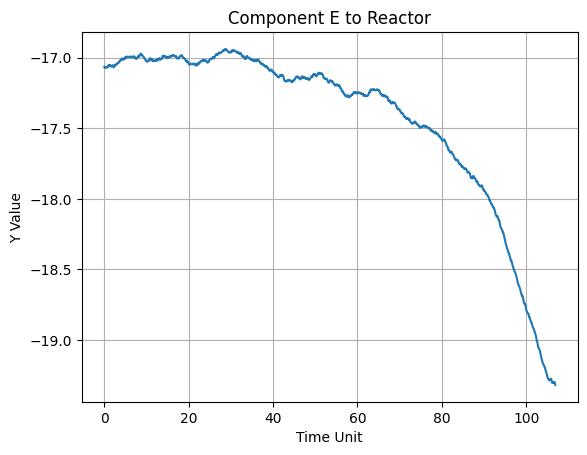

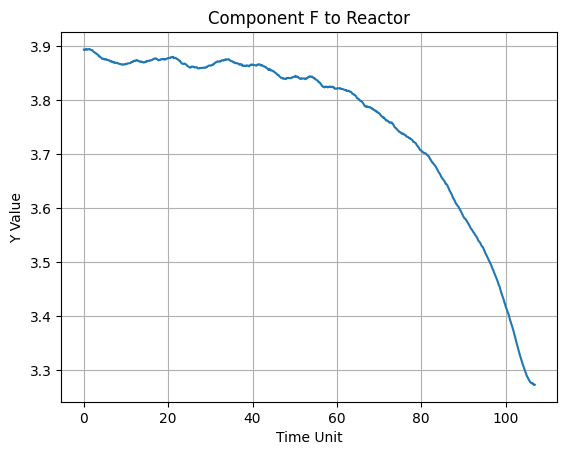

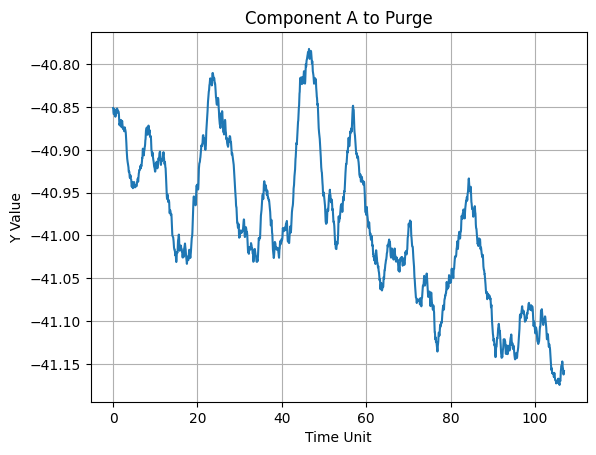

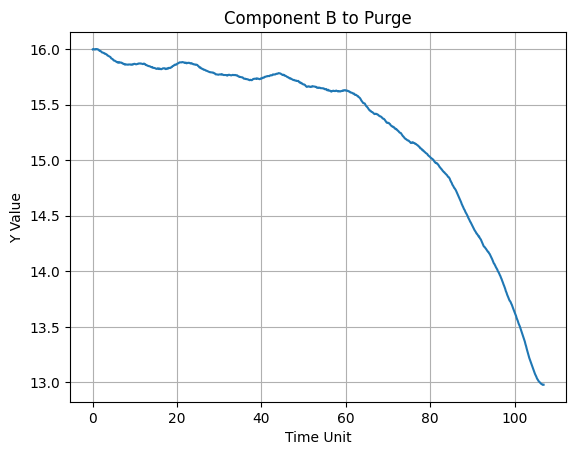

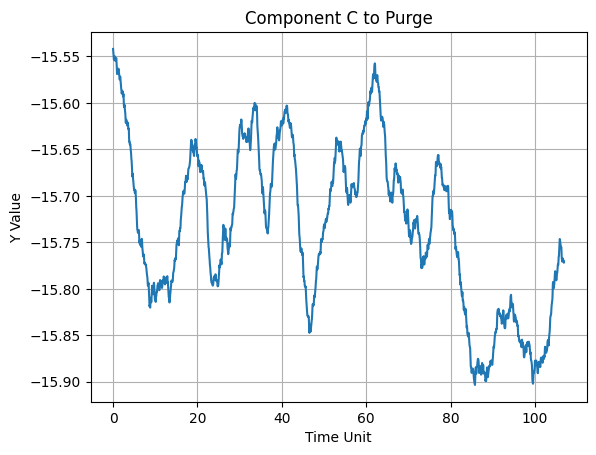

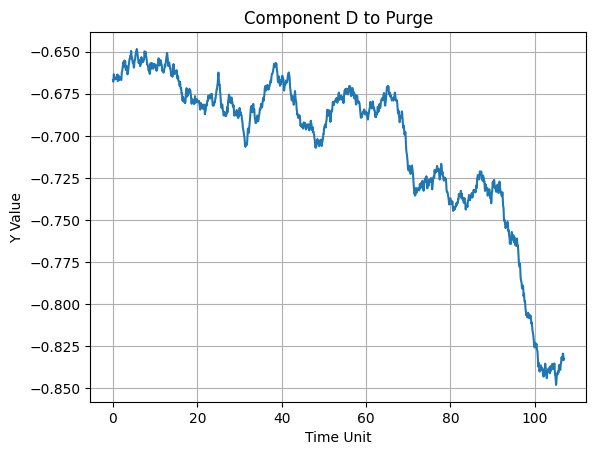

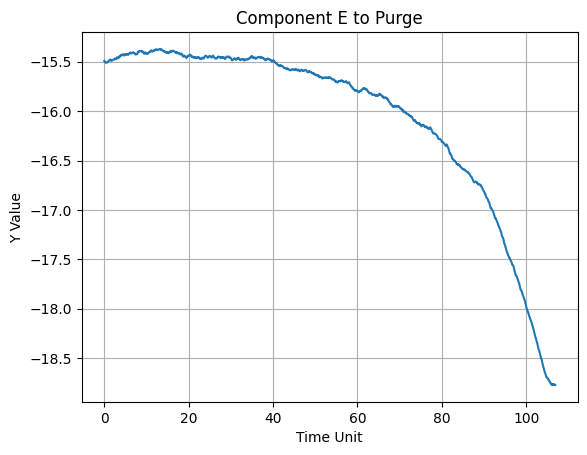

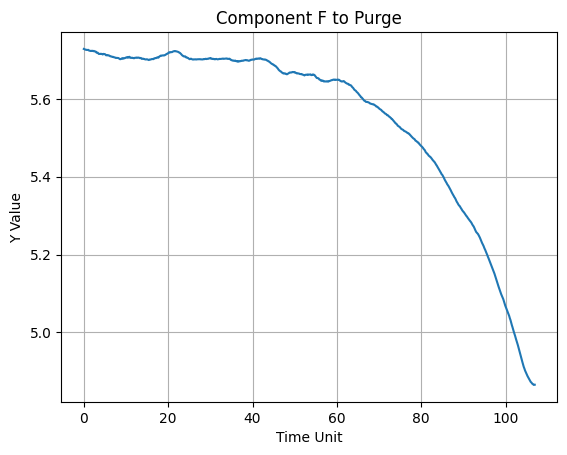

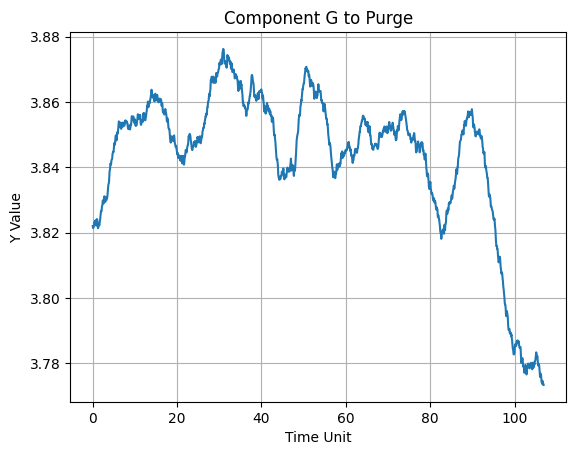

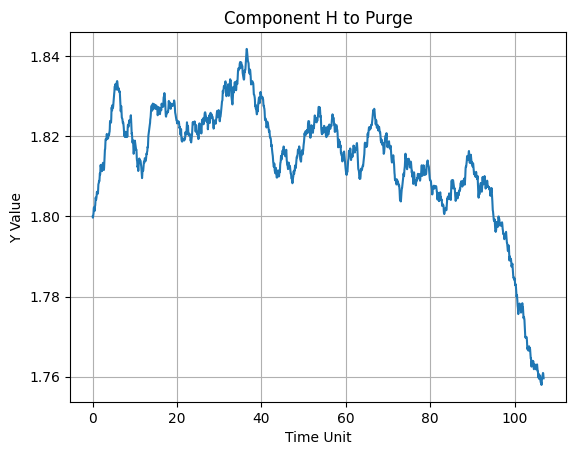

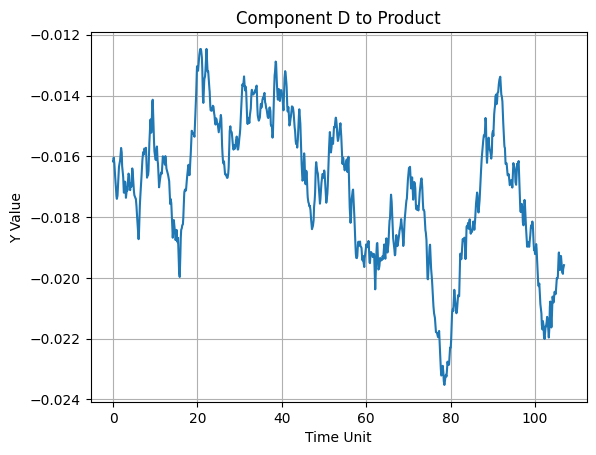

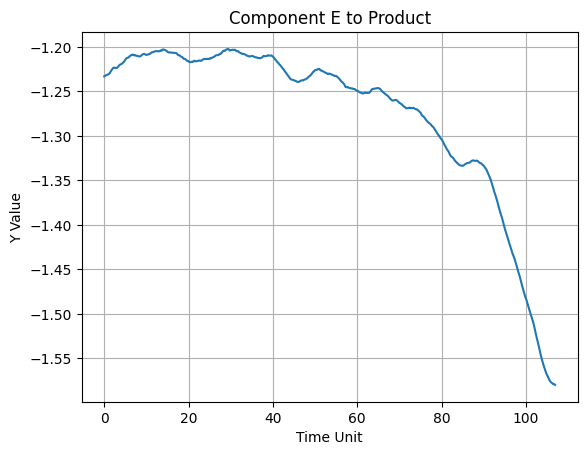

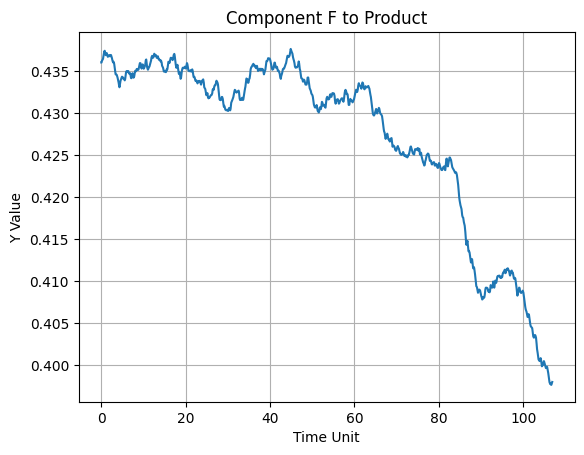

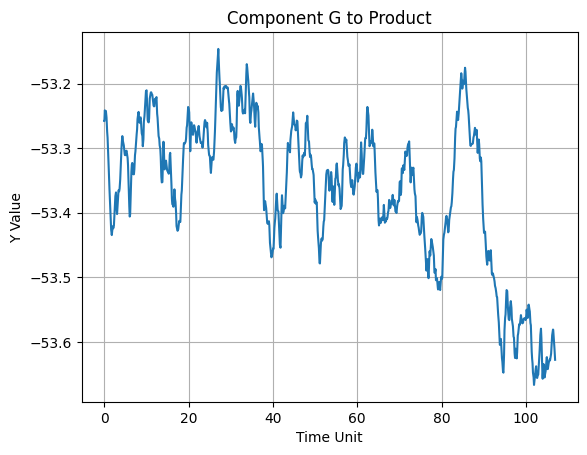

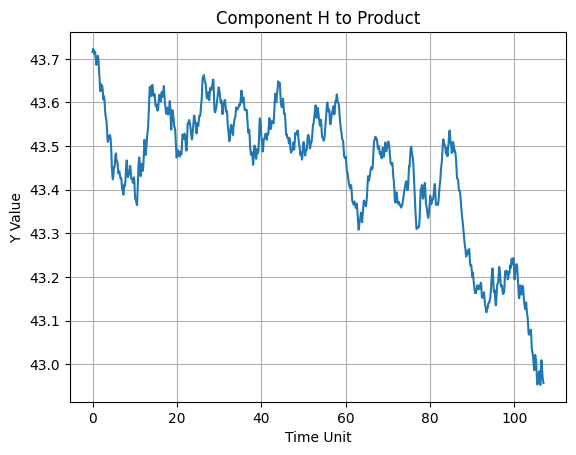

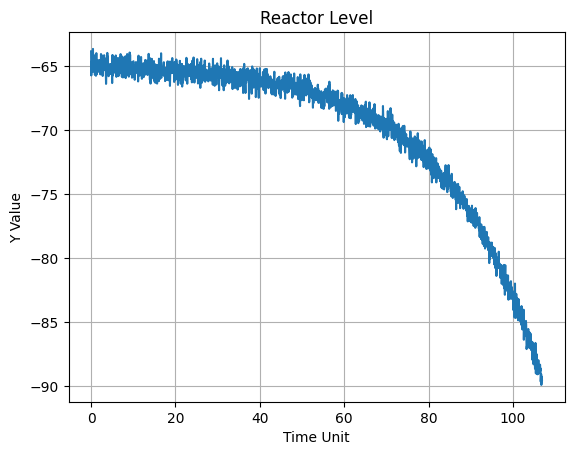

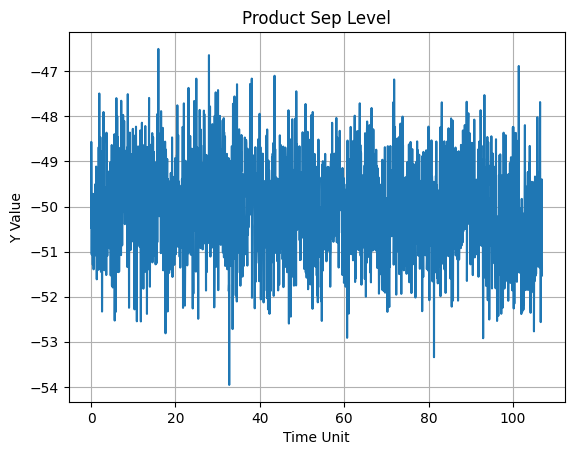

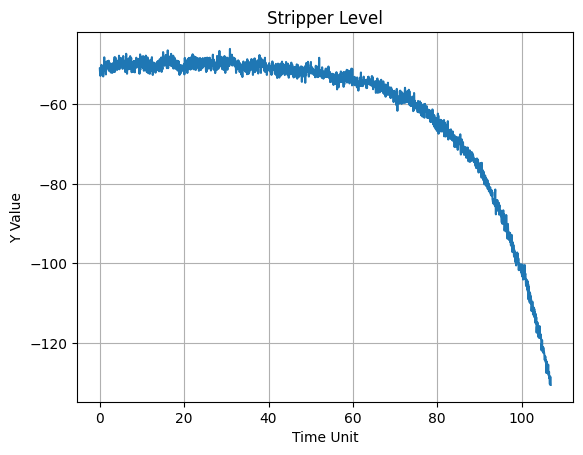

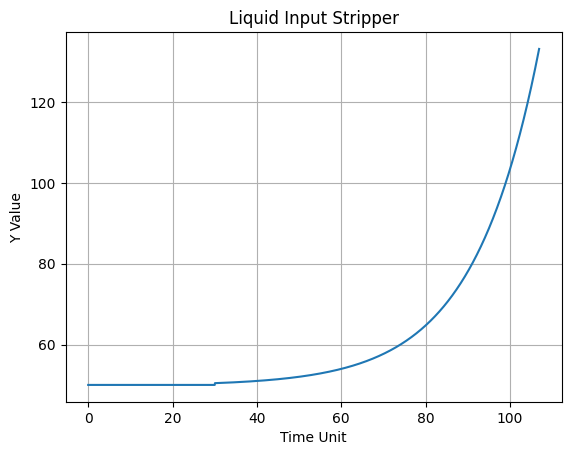

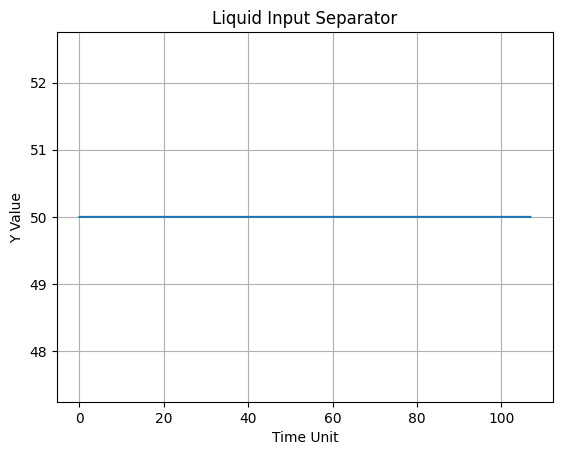

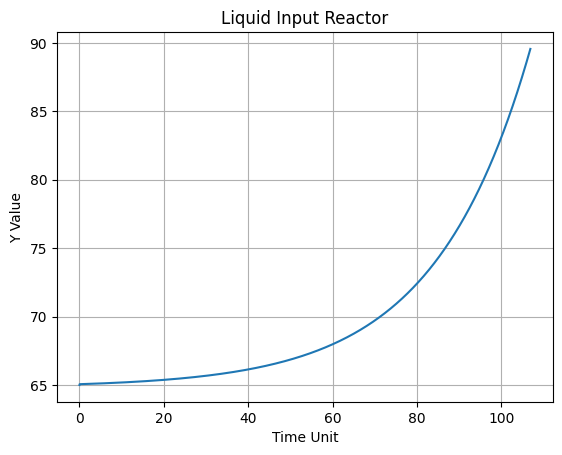

In [7]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= cleanData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [8]:
# Draw the data
print(cleanData)

{1:          Id    Time  environmentID      D feed     E Feed     A Feed  \
0         1    0.00              1  -99.852111  -9.432592 -21.923156   
1         1    0.05              1  -99.852044  -9.432261 -21.922731   
2         1    0.10              1  -99.852242  -9.431546 -21.924312   
3         1    0.15              1  -99.852566  -9.430474 -21.928005   
4         1    0.20              1  -99.852783  -9.429510 -21.932656   
...     ...     ...            ...         ...        ...        ...   
224023  100  114.95              1  100.000000 -10.171018 -23.288543   
224024  100  115.00              1  100.000000 -10.171858 -23.289266   
224025  100  115.05              1  100.000000 -10.172251 -23.289436   
224026  100  115.10              1  100.000000 -10.172429 -23.288432   
224027  100  115.15              1  100.000000 -10.172531 -23.288256   

        A and C Feed    Recycle      Purge  Separator  ...  \
0         -57.552641 -66.238401 -12.202576  32.744416  ...   
1      

### d. Normalize the data

In [9]:
norData             = preData.normalizeDataAllModes(movedData)                # Normalize the data
# print(norData)

Process:12875||2025-02-04 10:29:29,690-INFO [preProcessingDataTEP.py:normalizeDataAllModes():624]:Normalizing the data ...


D feed


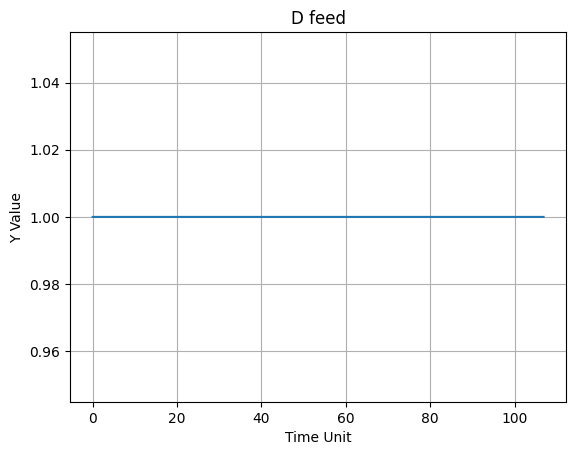

E Feed


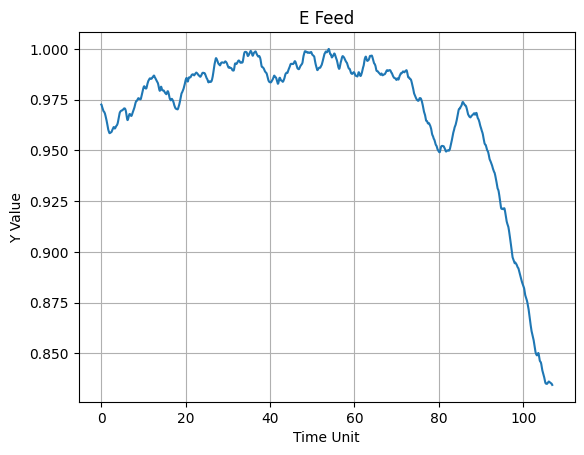

A Feed


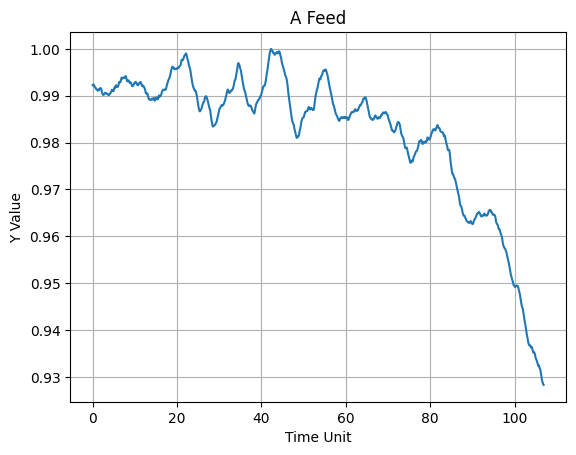

A and C Feed


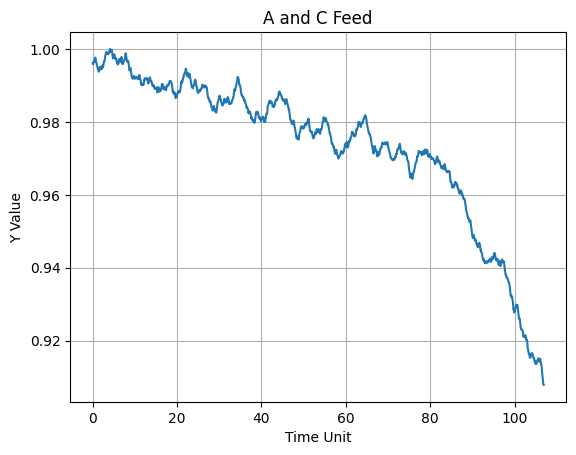

Recycle


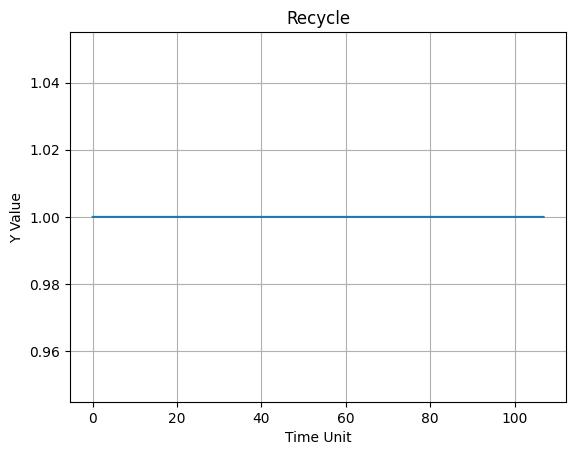

Purge


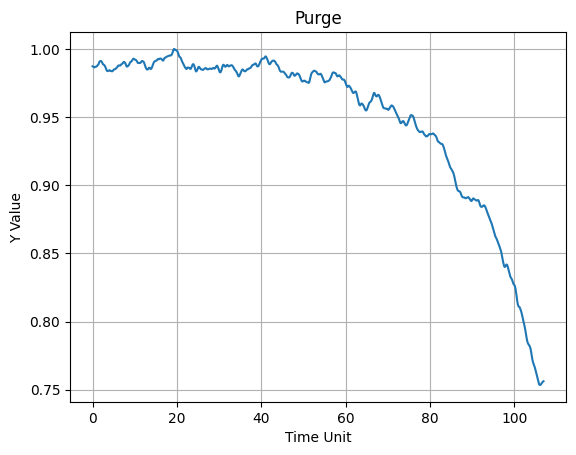

Separator


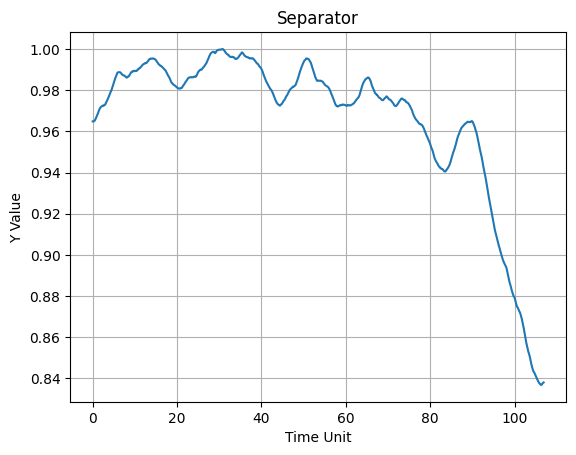

Stripper


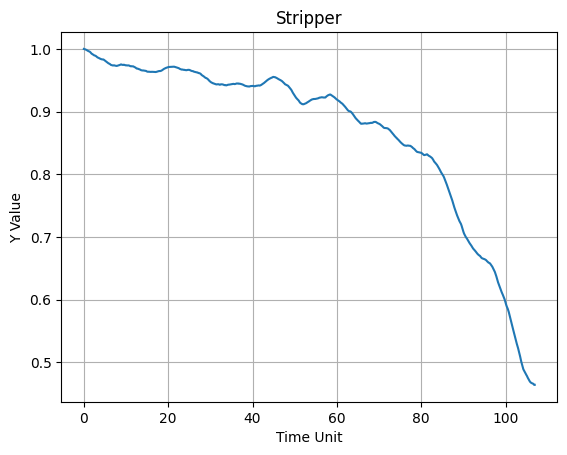

Steam


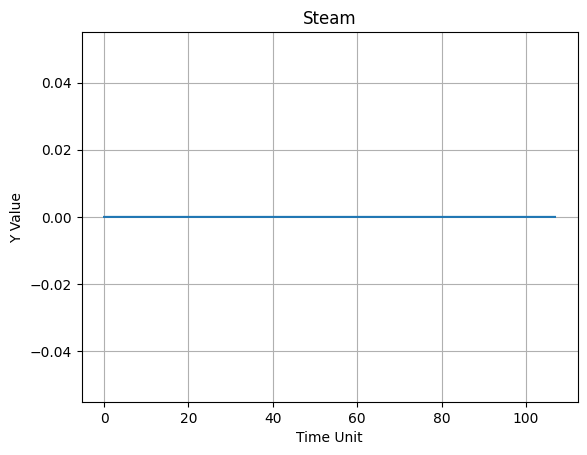

Reactor Coolant


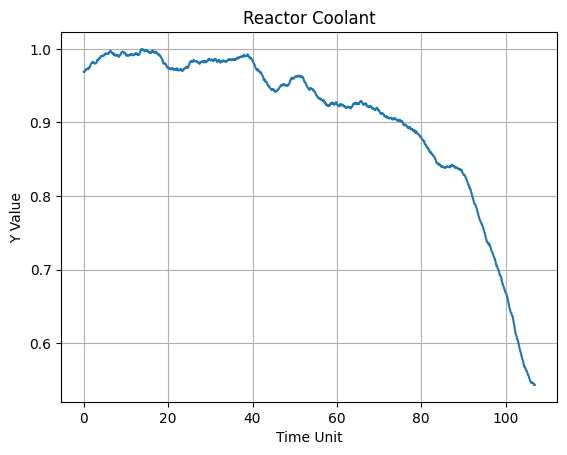

Condenser Coolant


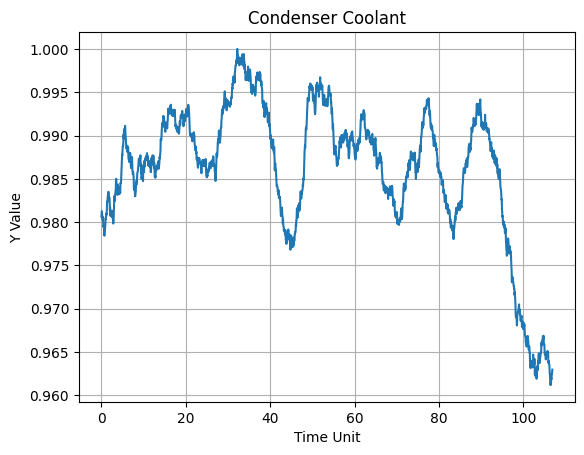

Agitator


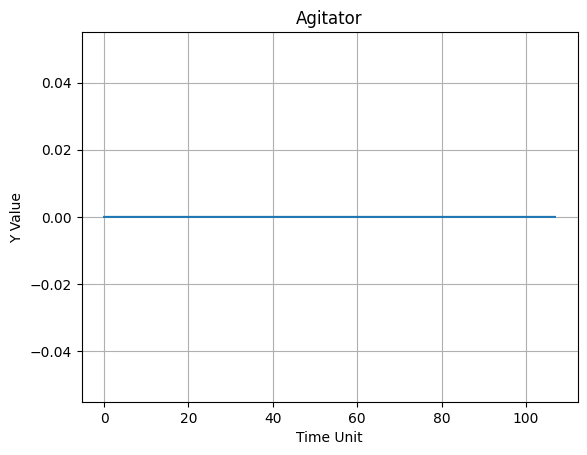

msv A Feed


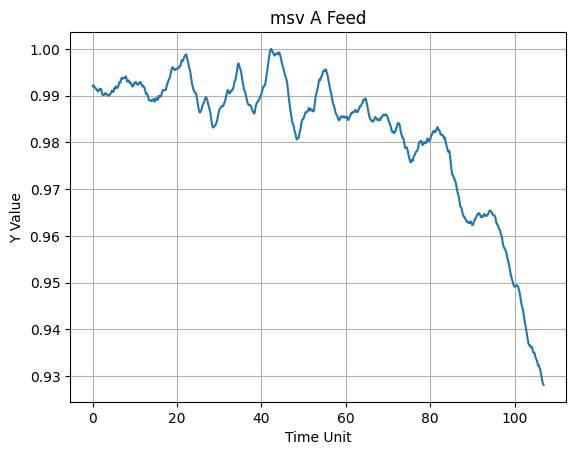

msv D Feed


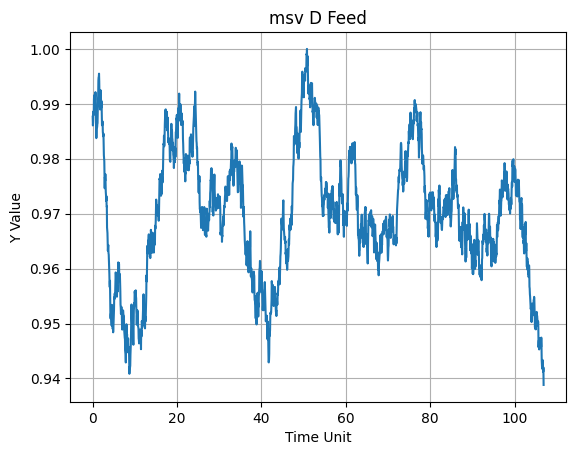

msv E Feed


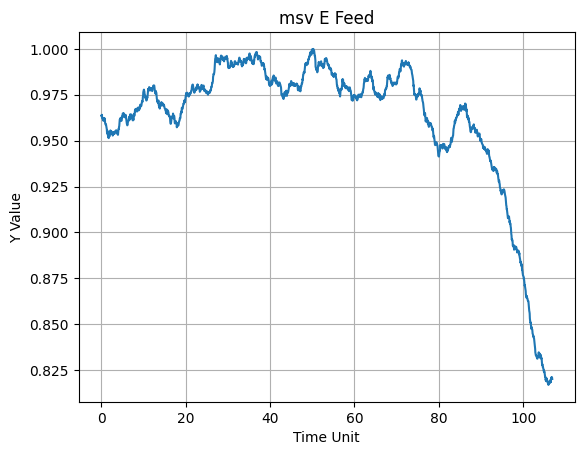

msv A and C Feed


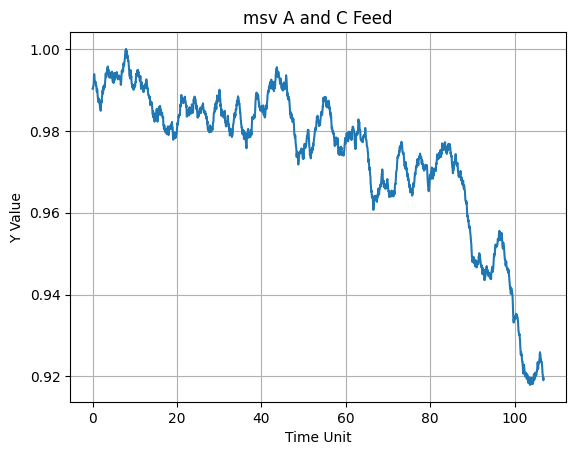

Recycle Flow


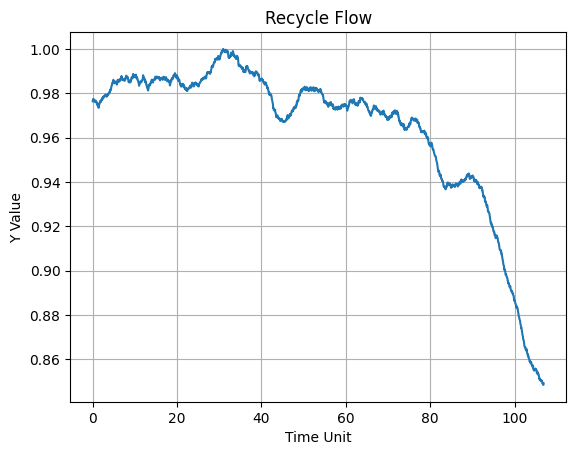

Reactor Feed Rate


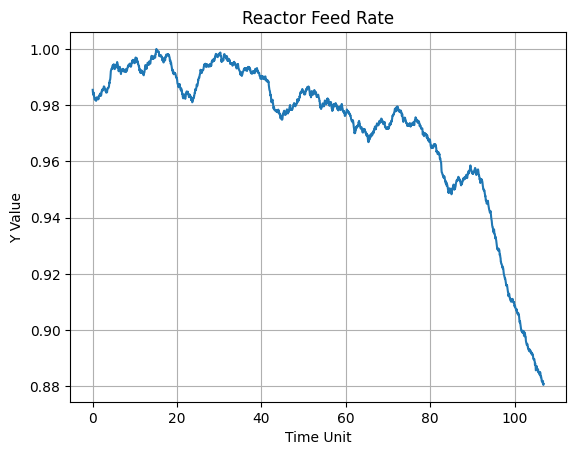

Reactor Pressure


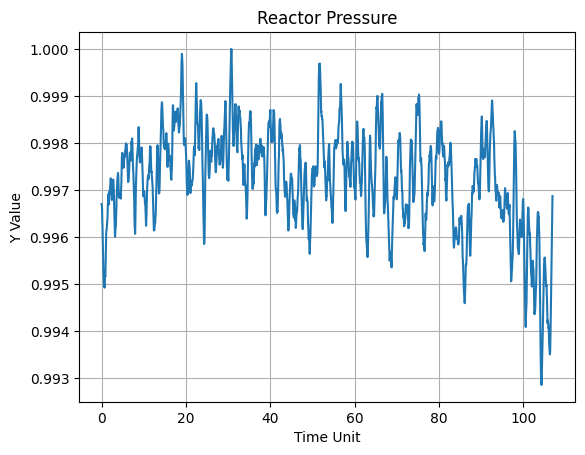

Reactor Temperature


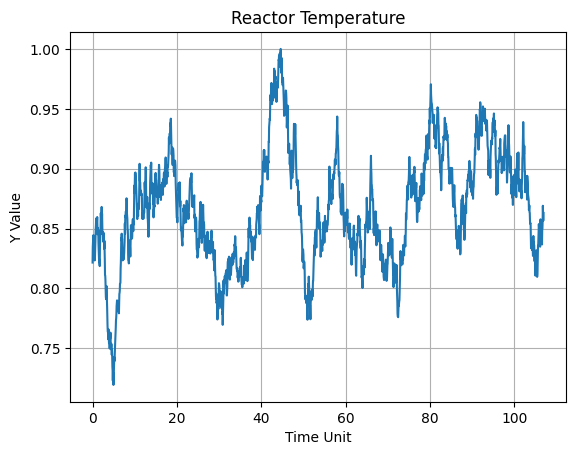

Purge Rate


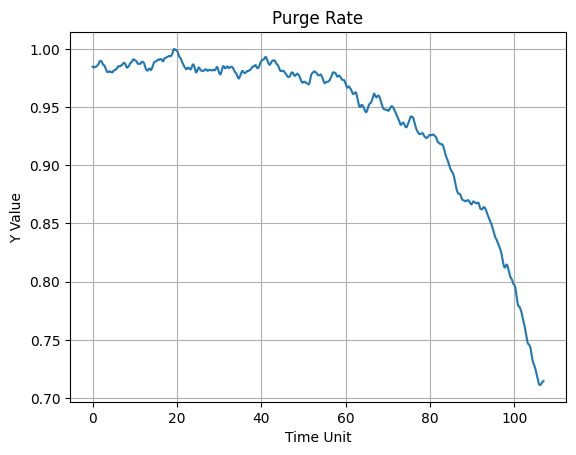

Product Sep Temp


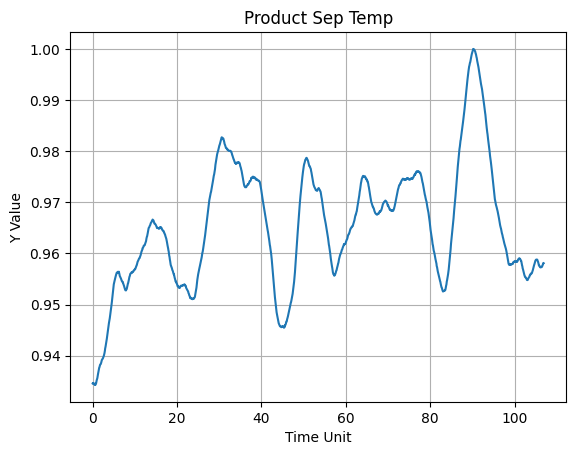

Product Sep Pressure


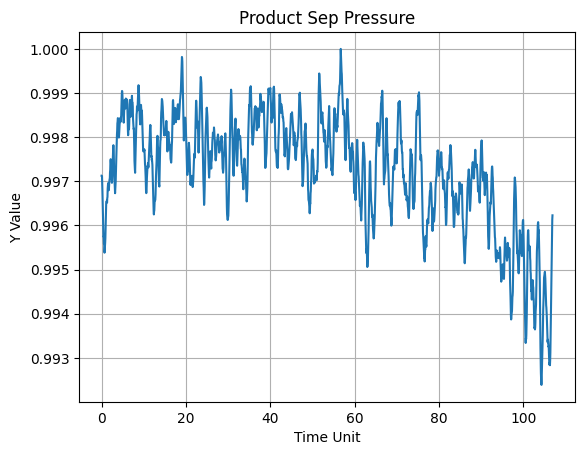

Product Sep Underflow


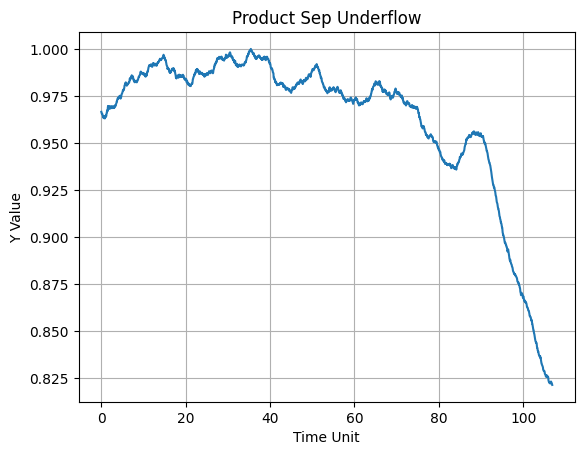

Stripper Pressure


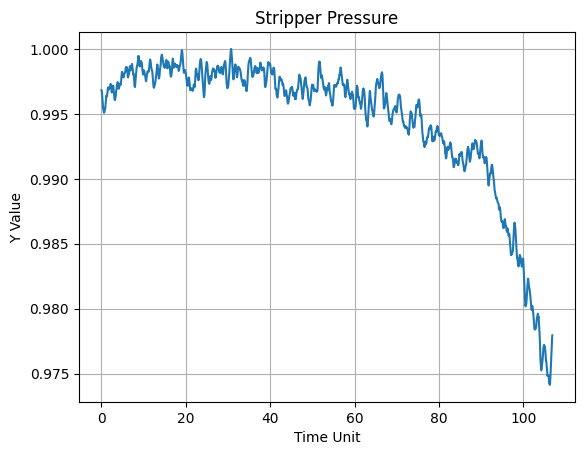

Reactor Coolant Temp


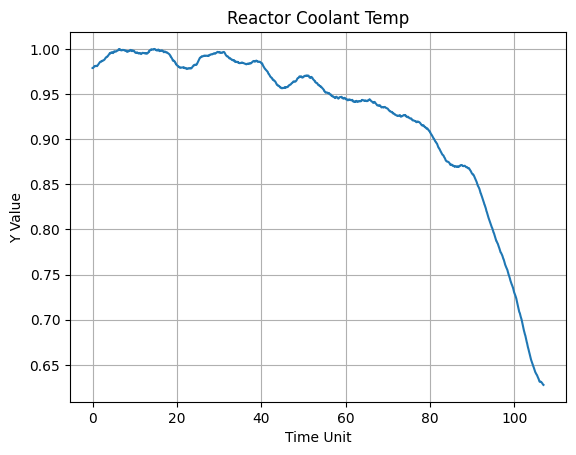

Stripper Underflow


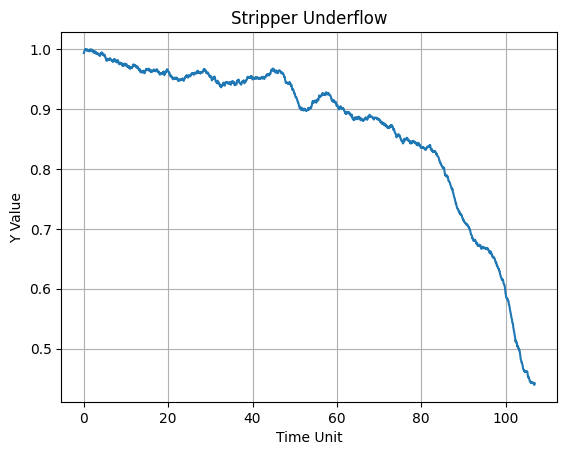

Stripper Temp


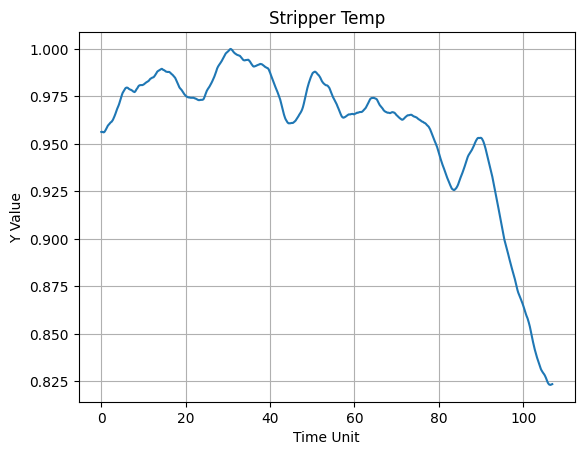

Stripper Steam Flow


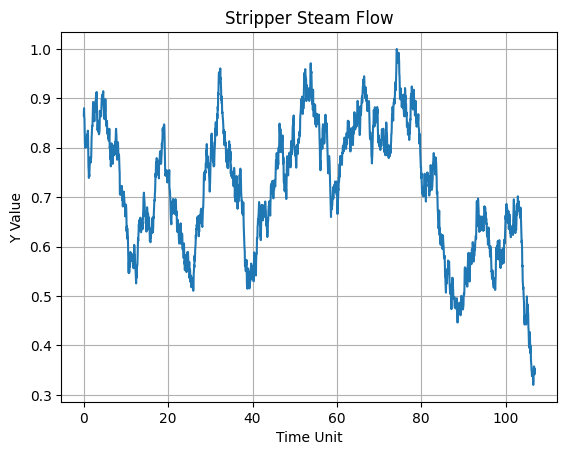

Compressor Work


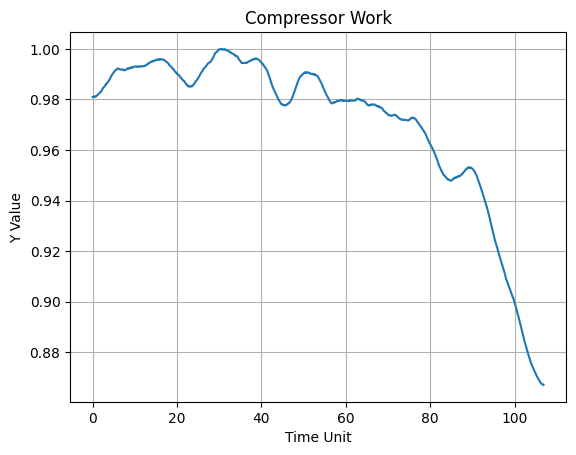

Separator Coolant Temp


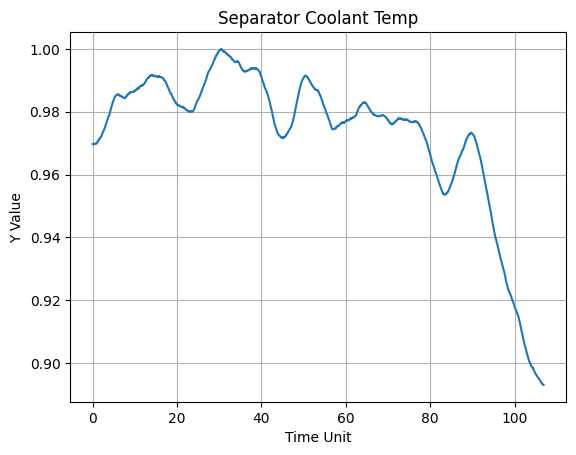

Component A to Reactor


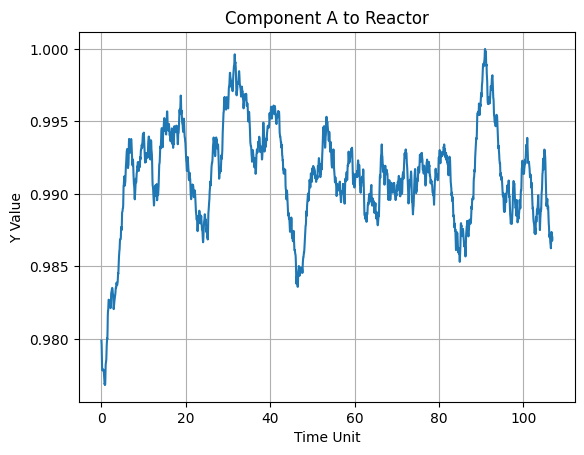

Component B to Reactor


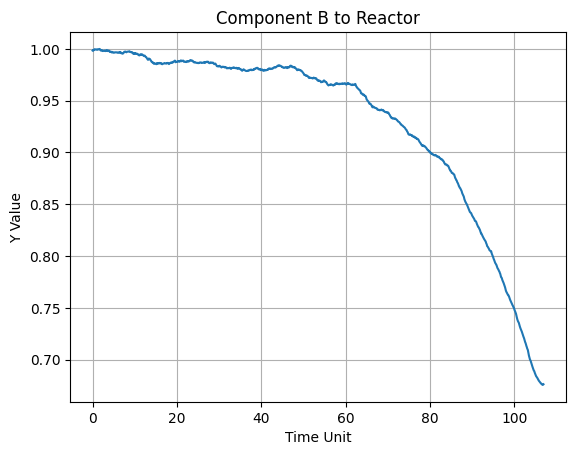

Component C to Reactor


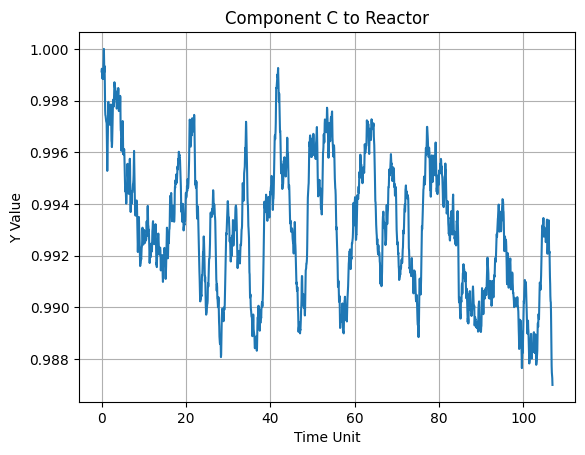

Component D to Reactor


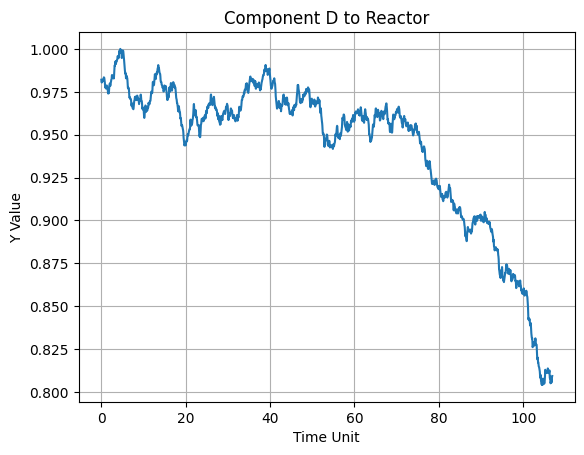

Component E to Reactor


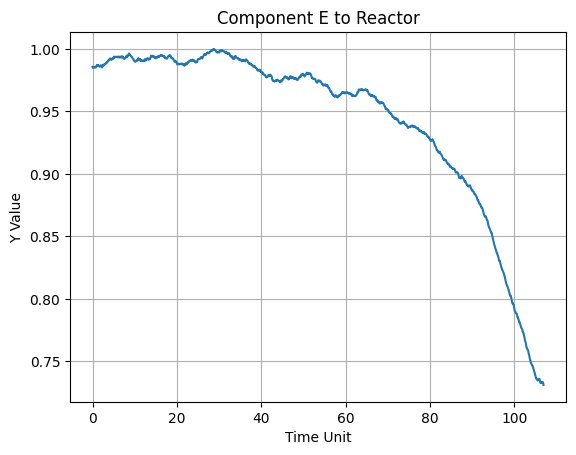

Component F to Reactor


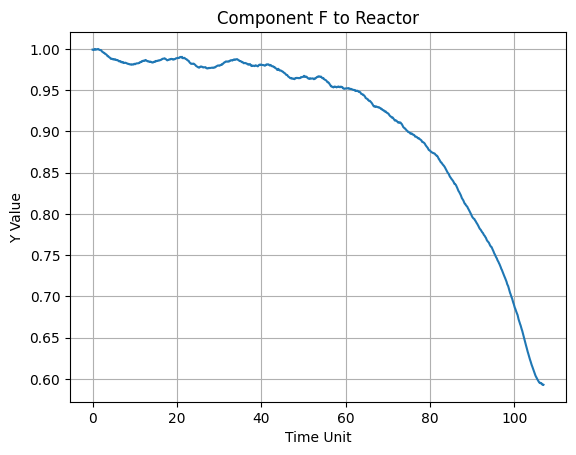

Component A to Purge


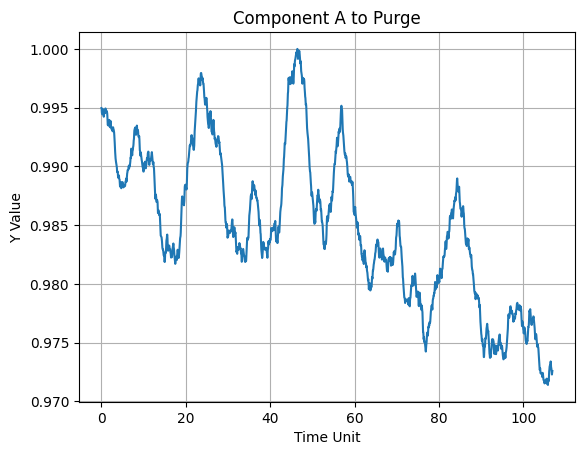

Component B to Purge


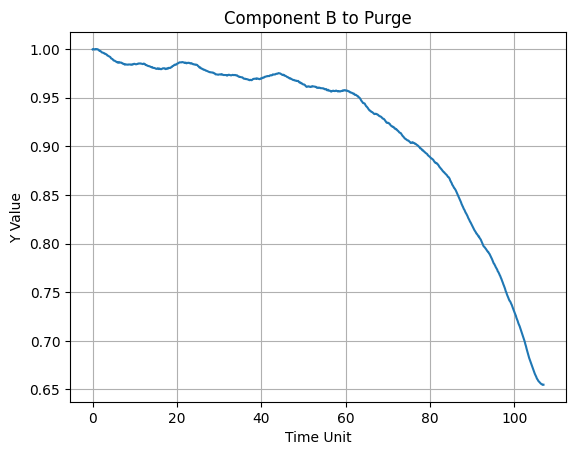

Component C to Purge


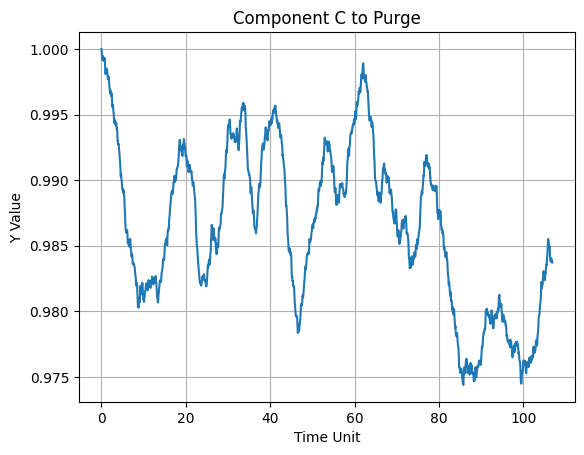

Component D to Purge


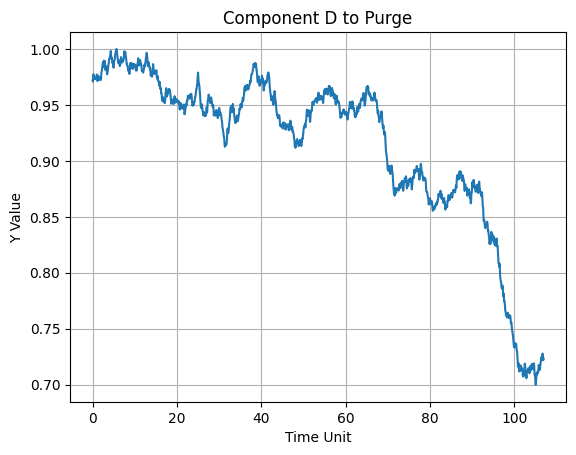

Component E to Purge


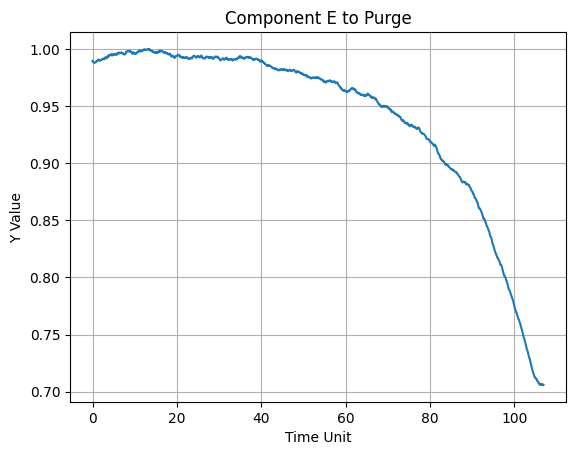

Component F to Purge


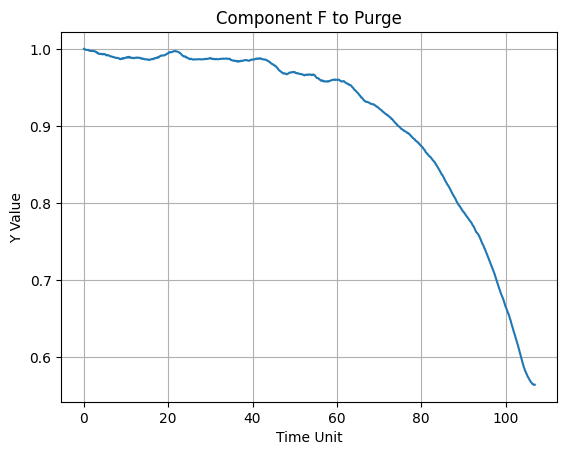

Component G to Purge


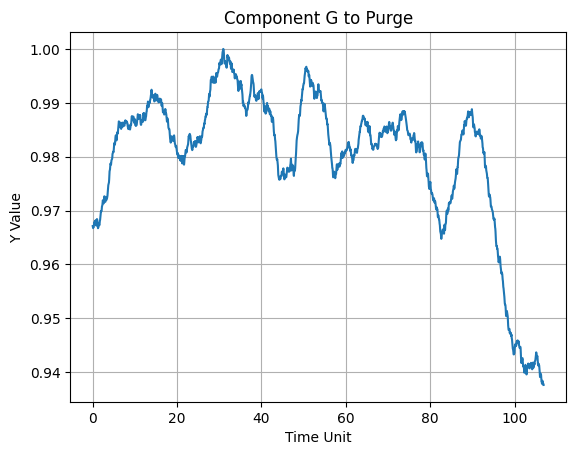

Component H to Purge


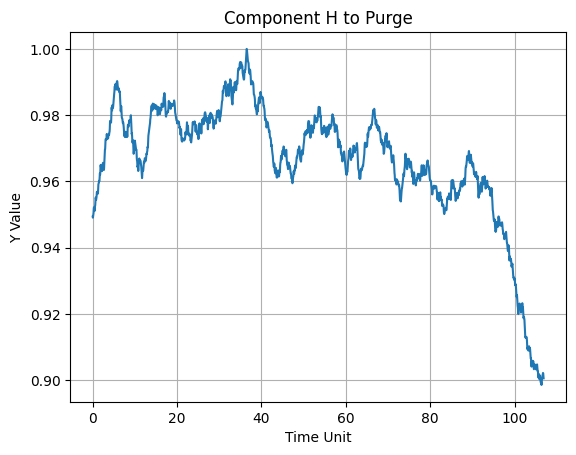

Component D to Product


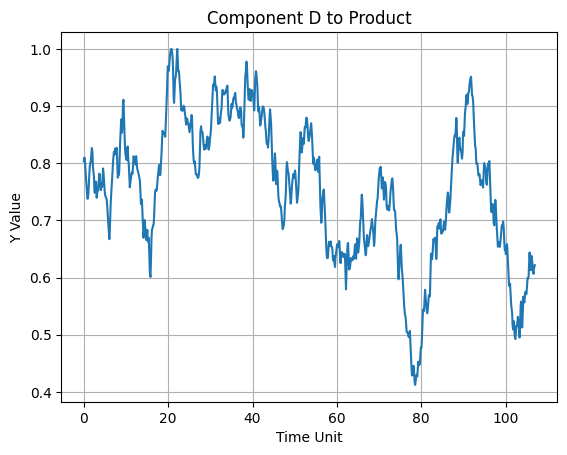

Component E to Product


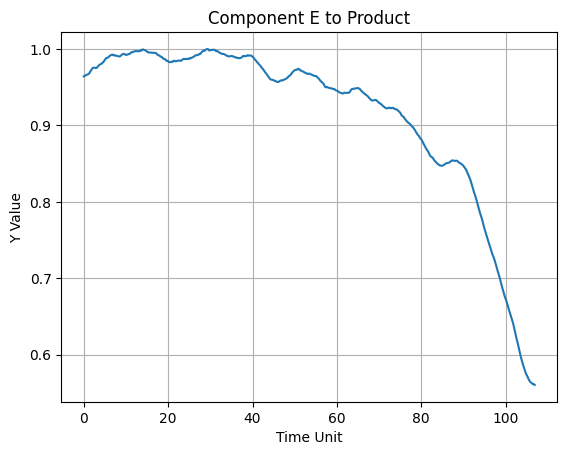

Component F to Product


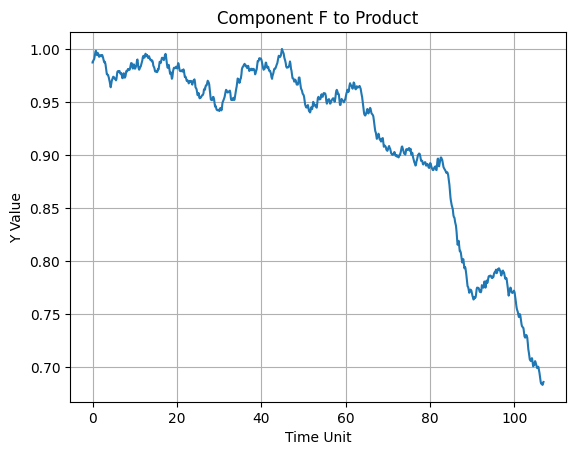

Component G to Product


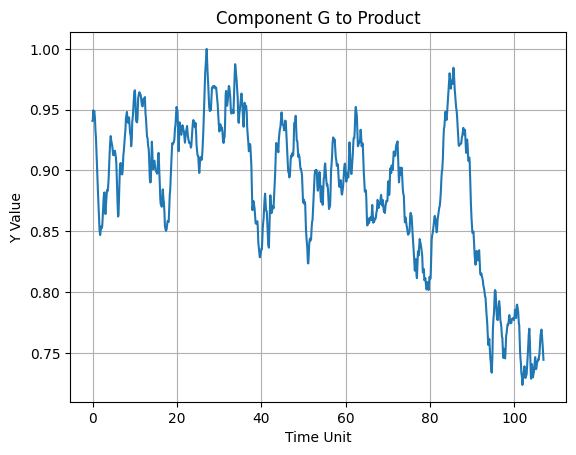

Component H to Product


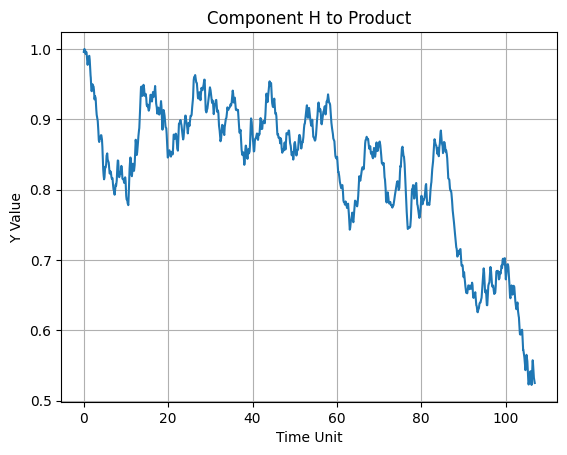

Reactor Level


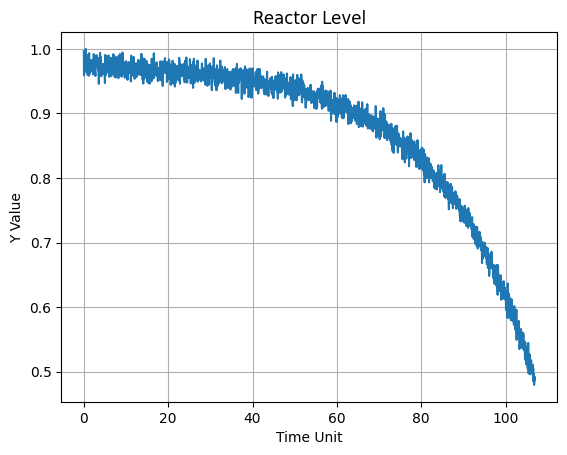

Product Sep Level


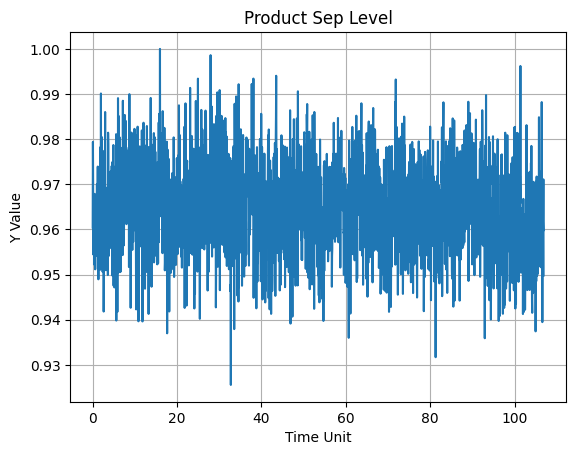

Stripper Level


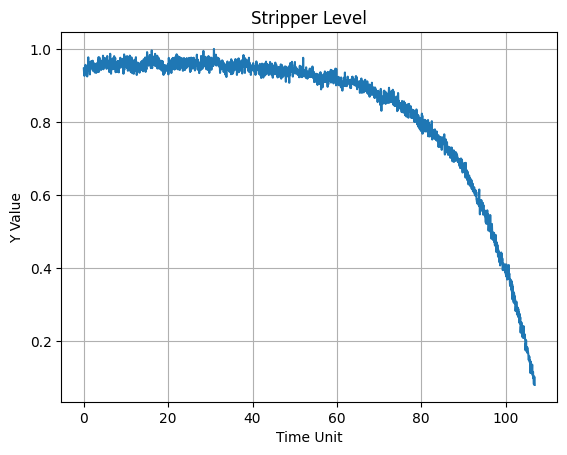

Liquid Input Stripper


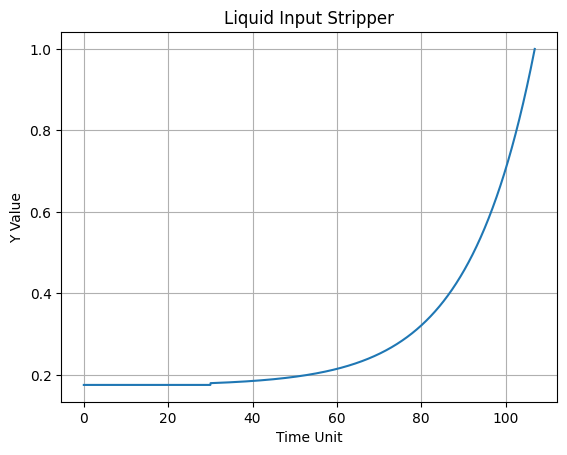

Liquid Input Separator


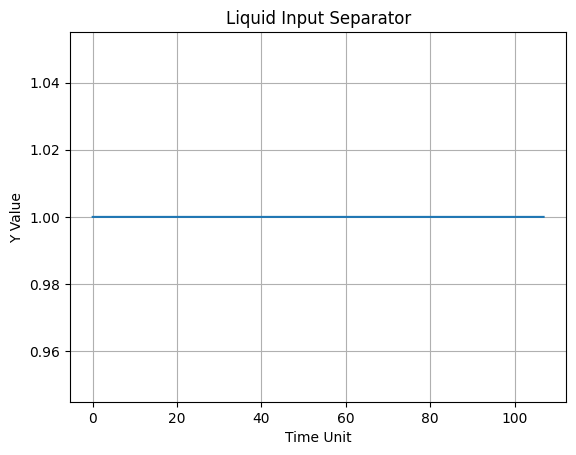

Liquid Input Reactor


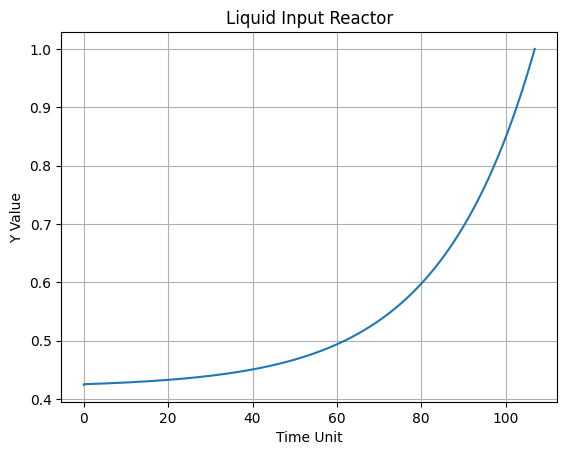

In [10]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData = norData, case = 2, idxTrajectory = 1)
for feature in preData.allHeadline:
    print(feature)
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [11]:
plot = MatPlot()

plot.subPlotMultiImg(inY = hi["reactor"],  numRow=20, numCol=5)

NameError: name 'hi' is not defined

### g. Split into each sequence

In [ ]:

seqTrainXY   = preData.getTensorData(norData, component =   "reactor", case = 1 )
# seqValXY   = preData.splitAllDataIntoSequences(valXY)  

# print(seqTrainXY[0].shape,seqTrainXY[1].shape)
# print(seqTrainXY[0][2011][:,0])

### h. Visualize the tensor data

In [ ]:

# Creating an array from 1 to 3000
#time = np.arange(1, 10)
# t= 0:200
# plot.draw1D(yCoor=seqTrainXY[1][0:t])
plot.draw1D(yCoor=seqTrainXY[0][2011][:,3])
            


# 4. Model and training

### To tensor

In [ ]:
tensorTrainXY       = data.TensorDataset(seqTrainXY[0],seqTrainXY[1])
tensorValXY         = data.TensorDataset(seqValXY[0],seqValXY[1])

In [ ]:
train_loader = data.DataLoader(tensorTrainXY,
                                batch_size  =   config.batch_size,
                                shuffle     =   False, 
                                num_workers =   config.num_workers)
        
val_loader = data.DataLoader(  tensorValXY, 
                                batch_size  =   config.val_batch_size, 
                                shuffle     =   False, 
                                num_workers =   config.num_workers)